In [2]:
import numpy as np
import math
import distribution.distribution_functions.random_mps as rmps
import distribution.distribution_functions.different_distribution_random_states_and_matrices as distrib
from distribution.distribution_functions.kl_divergence_tools import compute_kl_divergence_from_samples

In [13]:
n = 4
t = 0
print(rmps.generate_angle_product_state_eigenvalues(n))
print(rmps.generate_angle_maximally_entangled_eigenvalues(n))
print(rmps.generate_angles_between_max_entangled_and_product_state_eigenvalues(n, t))

[0.         1.57079633 1.57079633]
[1.04719755 0.95531662 0.78539816]
[1.04719755 0.95531662 0.78539816]


In [4]:
n = 1
L = 4
d = 2
t = 0.1
diameter_disk = 0.1
print()

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)


array([ 0.02435867+0.j,  0.1253361 +0.j,  0.15678285+0.j, -0.40037997+0.j,
       -0.38244199+0.j,  0.10449669+0.j, -0.40978442+0.j, -0.11742697+0.j,
       -0.13993032+0.j,  0.37327577+0.j,  0.13759194+0.j,  0.12612588+0.j,
       -0.29254281+0.j, -0.22610819+0.j,  0.35902882+0.j, -0.02543314+0.j])

In [2]:
t = 0.5
n = 4
angles_center = rmps.generate_angles_between_max_entangled_and_product_state_eigenvalues(n, t)
diameter_disk = 0.1
for _ in range(0, 15):
    point = rmps.random_point_on_the_n_sphere_around_max_entangled_state(n, diameter_disk, angles_center, r=1)
    print(point)

[0.86585432 0.15130468 0.18249786 0.44056523]
[0.86626944 0.15120161 0.18232046 0.43985746]
[0.86603043 0.1513705  0.18239678 0.4402382 ]
[0.8659295  0.15153478 0.18253384 0.44032342]
[0.8662735  0.15120387 0.18229144 0.4398607 ]
[0.86587319 0.15131046 0.18262299 0.44047429]
[0.8659351  0.15126561 0.18239531 0.44046234]
[0.86589342 0.15163553 0.18228227 0.44046388]
[0.86623515 0.15144401 0.18240556 0.4398063 ]
[0.8662493  0.1512832  0.18204252 0.43998416]
[0.86588554 0.15171456 0.18262071 0.44031193]
[0.86579353 0.15149596 0.18256738 0.44059015]
[0.86611306 0.15131023 0.18250088 0.44005319]
[0.86602842 0.15148679 0.18242875 0.44018891]
[0.8661425  0.1512348  0.18243379 0.44004899]


In [2]:
L = 4
d = 2
t = 0.5
diameter_disk = 0.01
n = d**L
# rmps.generate_angle_maximally_entangled_eigenvalues(n)
rmps.produce_a_random_mps_eigenvalues_in_a_disk_center_moving(L, d, t, diameter_disk)

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)


([array([[[ 0.46539862, -0.88510144]],
  
         [[ 0.88510114,  0.46539874]]]),
  array([[[-0.27960747, -0.87322513,  0.26356387,  0.29966053],
          [ 0.0092634 , -0.1944174 , -0.94270646,  0.2709376 ]],
  
         [[-0.952134  ,  0.20261917, -0.10917669, -0.20149222],
          [ 0.12384966, -0.39820191, -0.17311902, -0.892302  ]]]),
  array([[[ 0.46731228,  0.22455522],
          [ 0.30386179,  0.56584447],
          [ 0.03466302,  0.23738824],
          [ 0.5937594 , -0.45297647]],
  
         [[-0.13035086,  0.37835651],
          [-0.11228774, -0.43207032],
          [-0.5229644 , -0.03661021],
          [-0.18012393,  0.19153814]]]),
  array([[[ 0.23175049],
          [-0.32414456]],
  
         [[ 0.85633566],
          [ 0.32849849]]])],
 [np.float64(5.643787242507437e-14),
  np.float64(0.007023934581322728),
  np.float64(0.11609182921179396),
  np.float64(0.0022310620110954434)],
 [np.float64(5.546350240730036e-07),
  np.float64(0.0003664949257967434),
  np.float64(2.

In [3]:
# The function 1 has the Haar measure distribution. 
d = 2
L = 4 

args_dict_1 = {"L": L, "d": d}
func1 = rmps.random_state_vector_from_mps

def compute_kl_divergence_from_fcts(func1, func2, args_dict_1, args_dict_2, n_samples=10000, bins=50, range_proba=None):
    """
    Computes the Kullback–Leibler divergence between two distributions generated by func1 and func2.
    
    Parameters:
        func1 (callable): A function generating a random number from distribution P.
        func2 (callable): A function generating a random number from distribution Q.
        args_dict_1 (dict): A dictionary of arguments to pass to func1.
        args_dict_2 (dict): A dictionary of arguments to pass to func2.
        n_samples (int): Number of samples to draw from each function.
        bins (int): Number of bins to use for the histogram.
        range (tuple): The range of the histograms (min, max).
        
    Returns:
        kl_div (float): The KL divergence D_KL(P || Q).
        samples1 (np.array): The samples from the function P.
        samples2 (np.array): The sampels fron the function Q.
    """    
    # Generates n_samples random state vectors of dimension n.
    samples1 = np.array([func1(**args_dict_1) for _ in range(n_samples)])
    samples2 = np.array([func2(**args_dict_2) for _ in range(n_samples)])
    
    # Create histograms
    hist1, bin_edges = np.histogram(samples1, bins=bins, range=range_proba, density=True)
    hist2, _ = np.histogram(samples2, bins=bin_edges, density=True)
    
    # Avoid divide-by-zero and log(0) by replacing zero probabilities with a small value
    hist1 = np.clip(hist1, 1e-10, None)
    hist2 = np.clip(hist2, 1e-10, None)
    
    # Compute KL divergence
    kl_div = np.sum(hist1 * np.log(hist1 / hist2))
    
    return kl_div, samples1, samples2

In [4]:
kl,  samp1, samp2 = compute_kl_divergence_from_fcts(func1, func1, args_dict_1, args_dict_1, n_samples=100, bins=50, range_proba=None)
    

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:851: ComplexWarning: Casting complex values to real discards the imaginary part
  indices = f_indices.astype(np.intp)
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  db = np.array(np.diff(bin_edges), float)


In [9]:
bins = 50
hist1, bin_edges = np.histogram(samp1, bins=bins, range=None, density=True)
hist2, _ = np.histogram(samp2, bins=bin_edges, density=True)

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:851: ComplexWarning: Casting complex values to real discards the imaginary part
  indices = f_indices.astype(np.intp)
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  db = np.array(np.diff(bin_edges), float)


In [11]:
hist1, bin_edges


(array([0.0216386 , 0.0432772 , 0.06491581, 0.12983161, 0.08655441,
        0.19474742, 0.10819301, 0.32457903, 0.17310881, 0.32457903,
        0.47604924, 0.21638602, 0.60588085, 0.62751945, 0.86554407,
        0.71407386, 1.10356869, 1.08193009, 1.29831611, 1.2334003 ,
        1.25503891, 1.2117617 , 1.70944954, 1.38487052, 1.75272675,
        1.55797933, 1.57961793, 1.92583556, 1.2334003 , 1.44978632,
        1.31995471, 1.34159331, 1.06029149, 0.97373708, 0.69243526,
        0.56260365, 0.71407386, 0.62751945, 0.62751945, 0.32457903,
        0.34621763, 0.23802462, 0.28130182, 0.28130182, 0.12983161,
        0.12983161, 0.10819301, 0.0216386 , 0.0216386 , 0.06491581]),
 array([-0.73422321+0.j, -0.70533964+0.j, -0.67645607+0.j, -0.64757251+0.j,
        -0.61868894+0.j, -0.58980537+0.j, -0.56092181+0.j, -0.53203824+0.j,
        -0.50315467+0.j, -0.47427111+0.j, -0.44538754+0.j, -0.41650397+0.j,
        -0.38762041+0.j, -0.35873684+0.j, -0.32985327+0.j, -0.30096971+0.j,
        -0.272

In [3]:

kl = np.load("kl_divergence_result_Haar_measure_random_state_vs_mps_dirichlet_orthogonal.npy")
print(kl)

1.0062835655878555


In [4]:

try:
    # Load the samples
    samplesP = np.load("samplesQ_random_mps_not_simplified.npy")
    samplesQ = np.load("samplesQ_random_mps_simplified_nonordered_eigenvalues.npy")
    # Compute KL divergence
    kl_div = compute_kl_divergence_from_samples(samplesP, samplesQ, bins=100, range_proba=[-5,5])
except FileNotFoundError:
    print(f"File not found. Skipping.")

print(kl_div)

0.11481445837093202


In [10]:
print(samplesP.shape)

(10000, 16)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
import distribution.distribution_functions.different_distribution_random_states_and_matrices as distrib

In [ ]:


def generate_random_state(dim):
    """Generate a random state vector of given dimension."""
    state = np.random.randn(dim) + 1j * np.random.randn(dim)
    return state / np.linalg.norm(state)

def bipartition_and_svd(state, N):
    """Perform bipartition and SVD for each split of the state."""
    eigenvalue_distributions = []
    
    for n in range(1, N):
        dim_A, dim_B = n, N // n
        if N % n != 0:
            continue  # Ensure dimensions are compatible
        
        # Reshape into bipartition form
        reshaped_state = state.reshape(dim_A, dim_B)
        
        # Singular value decomposition
        _, singular_values, _ = svd(reshaped_state)
        eigenvalues = singular_values**2  # Eigenvalues of the reduced density matrix
        eigenvalue_distributions.append(eigenvalues)
    
    return eigenvalue_distributions

def plot_density_distributions(distributions):
    """Plot density distributions of eigenvalues."""
    for i, eigenvalues in enumerate(distributions):
        plt.hist(eigenvalues, bins=30, density=True, alpha=0.5, label=f"Bipartition {i+1}")
    
    plt.xlabel("Eigenvalue")
    plt.ylabel("Density")
    plt.legend()
    plt.title("Density Distribution of Eigenvalues")
    plt.show()

# Main script
N = 16  # Example dimension
state = (N)
eigenvalue_distributions = bipartition_and_svd(state, N)
plot_density_distributions(eigenvalue_distributions)


/tmp/ipykernel_2298567/1291203930.py:8: RuntimeWarning: invalid value encountered in arcsin
  y_values = np.arcsin((1 + a_values) / (1 - a_values))


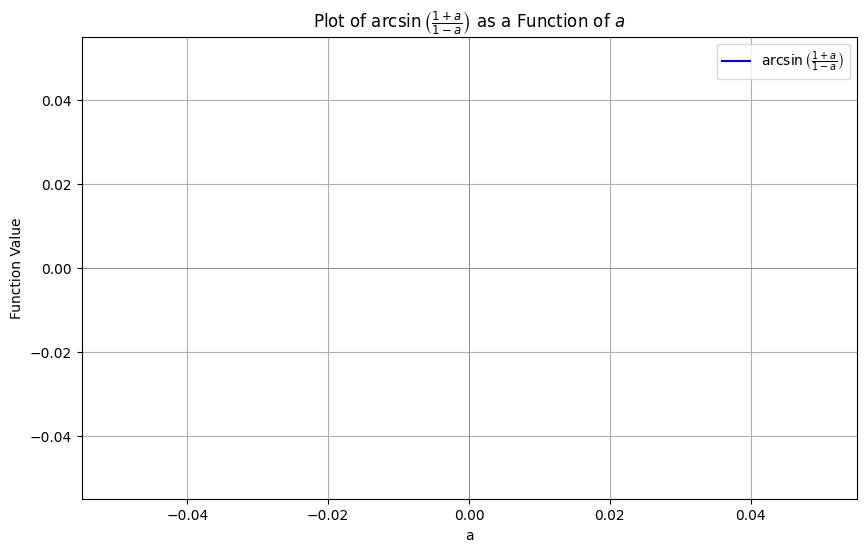

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Define the range of 'a' values, avoiding a = 1 to prevent division by zero
a_values = np.linspace(0.1, 0.99, 1000)

# Compute the corresponding arcsin values
y_values = np.arcsin((1 + a_values) / (1 - a_values))

# Plot the function
plt.figure(figsize=(10, 6))
plt.plot(a_values, y_values, label=r'$\arcsin\left(\frac{1+a}{1-a}\right)$', color='blue')
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('a')
plt.ylabel('Function Value')
plt.title(r'Plot of $\arcsin\left(\frac{1+a}{1-a}\right)$ as a Function of $a$')
plt.legend()
plt.grid(True)

plt.show()


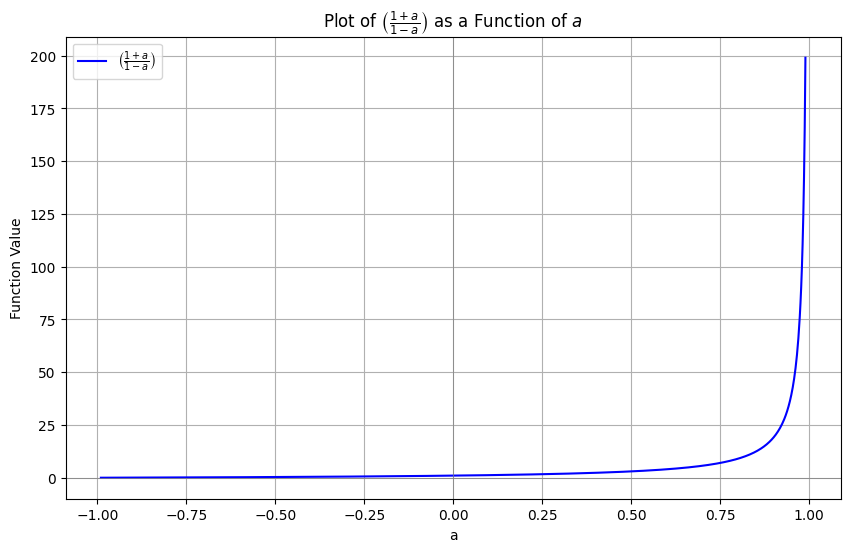

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Define the range of 'a' values, avoiding a = 1 to prevent division by zero
a_values = np.linspace(-0.99, 0.99, 1000)

# Compute the corresponding arcsin values
y_values = (1 + a_values) / (1 - a_values)

# Plot the function
plt.figure(figsize=(10, 6))
plt.plot(a_values, y_values, label=r'$\left(\frac{1+a}{1-a}\right)$', color='blue')
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('a')
plt.ylabel('Function Value')
plt.title(r'Plot of $\left(\frac{1+a}{1-a}\right)$ as a Function of $a$')
plt.legend()
plt.grid(True)

plt.show()


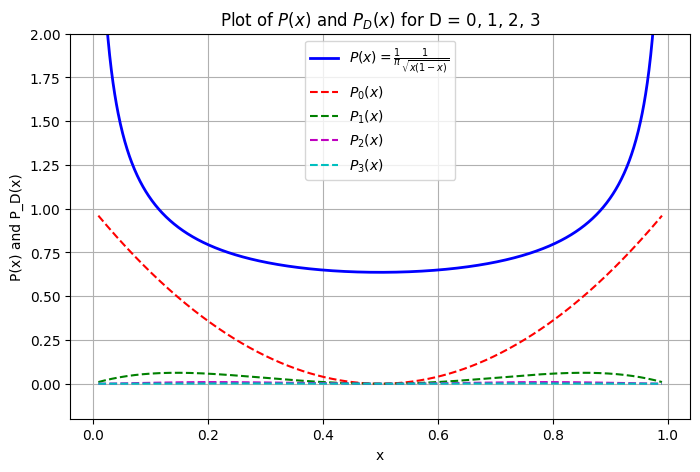

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define the main function P(x)
def P(x):
    return (1 / np.pi) * (1 / np.sqrt(x * (1 - x)))

# Define the family of functions P_D(x)
def P_D(x, D):
    return (1 - x)**D * x**D * (x - (1 - x))**2

# Define x values avoiding singularities at 0 and 1
x = np.linspace(0.01, 0.99, 1000)  # Avoid exact 0 and 1

# Compute P(x)
y_P = P(x)

# Plot P(x)
plt.figure(figsize=(8, 5))
plt.plot(x, y_P, label=r"$P(x) = \frac{1}{\pi} \frac{1}{\sqrt{x(1-x)}}$", color='b', linewidth=2)

# Plot P_D(x) for D = 0, 1, 2, 3
colors = ['r', 'g', 'm', 'c']
for i, D in enumerate([0, 1, 2, 3]):
    y_P_D = P_D(x, D)
    plt.plot(x, y_P_D, label=fr"$P_{{{D}}}(x)$", color=colors[i], linestyle='--')

# Labels and title
plt.xlabel("x")
plt.ylabel("P(x) and P_D(x)")
plt.title("Plot of $P(x)$ and $P_D(x)$ for D = 0, 1, 2, 3")
plt.ylim(-0.2, 2)  # Adjusting y-limits for better visualization
plt.legend()
plt.grid()
plt.show()


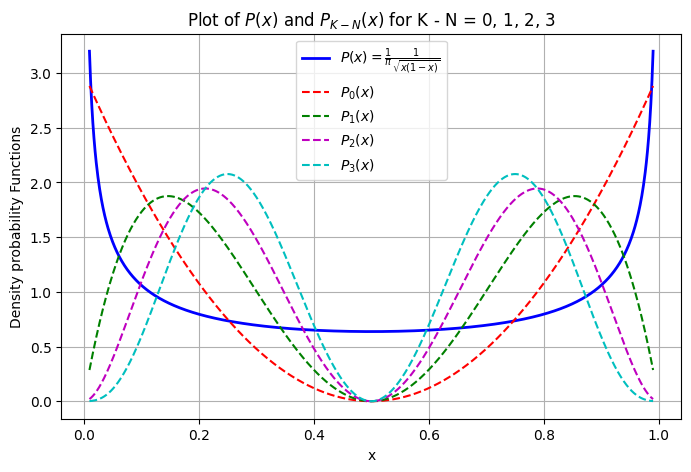

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P_D(x)
def P_D(x, D):
    return (1 - x)**D * x**D * (x - (1 - x))**2

# Compute normalization constant Z_D numerically
def compute_Z_D(D):
    integral, _ = quad(P_D, 0, 1, args=(D,))
    return integral

# Define the normalized probability density function
def P_D_normalized(x, D):
    Z_D = compute_Z_D(D)
    return P_D(x, D) / Z_D

# Define the main function P(x)
def P(x):
    return (1 / np.pi) * (1 / np.sqrt(x * (1 - x)))

# Define x values avoiding singularities at 0 and 1
x = np.linspace(0.01, 0.99, 1000)  # Avoid exact 0 and 1

# Compute P(x)
y_P = P(x)

# Plot P(x)
plt.figure(figsize=(8, 5))
plt.plot(x, y_P, label=r"$P(x) = \frac{1}{\pi} \frac{1}{\sqrt{x(1-x)}}$", color='b', linewidth=2)

# Plot normalized P_D(x) for D = 0, 1, 2, 3
colors = ['r', 'g', 'm', 'c']
for i, D in enumerate([0, 1, 2, 3]):
    y_P_D_norm = np.array([P_D_normalized(xi, D) for xi in x])
    plt.plot(x, y_P_D_norm, label=fr"$P_{{{D}}}(x)$", color=colors[i], linestyle='--')

# Labels and title
plt.xlabel("x")
plt.ylabel("Density probability Functions")
plt.title("Plot of $P(x)$ and $P_{K-N}(x)$ for K - N = 0, 1, 2, 3")
plt.legend()
plt.grid()
plt.show()


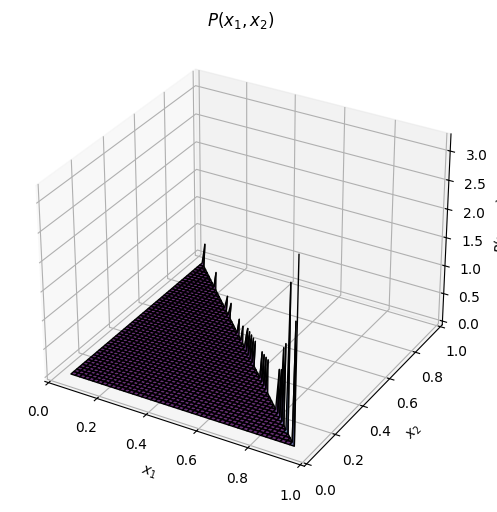

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the function P(x1, x2)
def P(x1, x2):
    with np.errstate(divide='ignore', invalid='ignore'):  # Handle singularities safely
        P_val = (1 / np.pi)**2 * (1 / np.sqrt(x1 * (1 - x1))) * (1 / np.sqrt(x2 * (1 - x1 - x2)))
        P_val[(x1 + x2) > 1] = np.nan  # Remove values where x1 + x2 > 1
    return P_val

# Define grid points for x1 and x2
N = 100  # Resolution
x1_vals = np.linspace(0.05, 0.95, N)  # Avoid exact singularities
x2_vals = np.linspace(0.05, 0.95, N)
X1, X2 = np.meshgrid(x1_vals, x2_vals)

# Compute P(x1, x2) while ensuring x1 + x2 <= 1
Z = P(X1, X2)

# Create a mask for the valid region (x1 + x2 <= 1)
# Z[np.isnan(Z)] = 0  # Replace NaNs for cleaner plotting
# Z[Z>0.5] =  np.nan  # Replace NaNs for cleaner plotting

# Plot in 3D
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X1, X2, Z, cmap='viridis', edgecolor='k', alpha=0.8)

# Labels
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_zlabel(r"$P(x_1, x_2)$")
ax.set_title(r"$P(x_1, x_2)$")

plt.show()


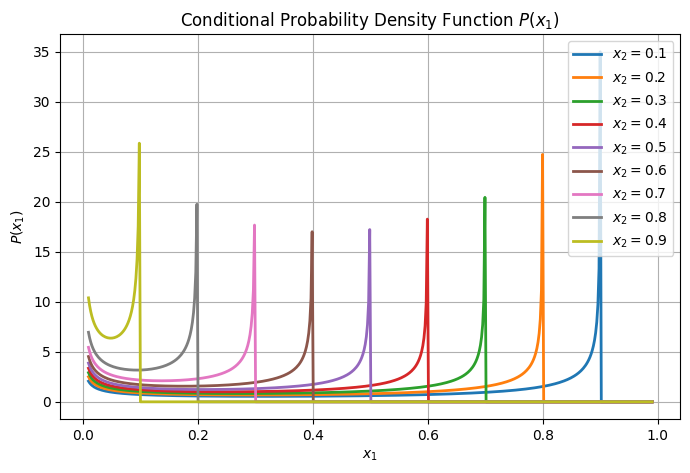

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P(x1, x2)
def P(x1, x2):
    if x1 + x2 > 1 or x1 <= 0 or x2 <= 0 or (1 - x1 - x2) <= 0:
        return 0  # Ensure function is zero outside valid region
    return (1 / np.pi)**2 * (1 / np.sqrt(x1 * (1 - x1))) * (1 / np.sqrt(x2 * (1 - x1 - x2)))

# Compute the normalization constant Z(x2) numerically
def compute_Z(x2):
    integral, _ = quad(lambda x1: P(x1, x2), 0, 1 - x2)
    return integral

# Define the normalized probability density function
def P_normalized(x1, x2):
    Z_x2 = compute_Z(x2)
    return P(x1, x2) / Z_x2 if Z_x2 != 0 else 0  # Avoid division by zero

# Define x1 values avoiding singularities
x1_vals = np.linspace(0.01, 0.99, 500)  # Avoid exact 0 and 1

# Different values of x2 to plot
x2_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

# Create the plot
plt.figure(figsize=(8, 5))

for x2 in x2_values:
    P_vals = np.array([P_normalized(x1, x2) for x1 in x1_vals])  # Compute normalized P(x1)
    plt.plot(x1_vals, P_vals, label=fr"$x_2 = {x2}$", linewidth=2)

# Labels and title
plt.xlabel(r"$x_1$")
plt.ylabel(r"$P(x_1)$")
plt.title(r"Conditional Probability Density Function $P(x_1)$")
plt.legend()
plt.grid()
plt.show()


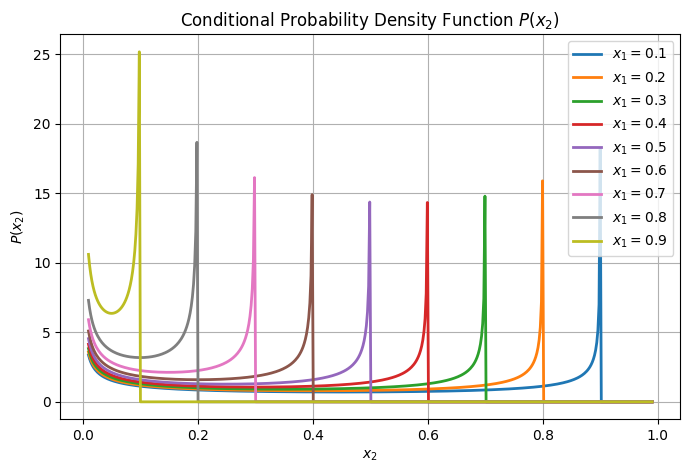

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P(x1, x2)
def P(x1, x2):
    if x1 + x2 > 1 or x1 <= 0 or x2 <= 0 or (1 - x1 - x2) <= 0:
        return 0  # Ensure function is zero outside valid region
    return (1 / np.pi)**2 * (1 / np.sqrt(x1 * (1 - x1))) * (1 / np.sqrt(x2 * (1 - x1 - x2)))

# Compute the normalization constant Z(x1) numerically
def compute_Z(x1):
    integral, _ = quad(lambda x2: P(x1, x2), 0, 1 - x1)
    return integral

# Define the normalized probability density function
def P_normalized(x1, x2):
    Z_x1 = compute_Z(x1)
    return P(x1, x2) / Z_x1 if Z_x1 != 0 else 0  # Avoid division by zero

# Define x2 values avoiding singularities
x2_vals = np.linspace(0.01, 0.99, 500)  # Avoid exact 0 and 1

# Different values of x1 to plot
x1_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

# Create the plot
plt.figure(figsize=(8, 5))

for x1 in x1_values:
    P_vals = np.array([P_normalized(x1, x2) for x2 in x2_vals])  # Compute normalized P(x2)
    plt.plot(x2_vals, P_vals, label=fr"$x_1 = {x1}$", linewidth=2)

# Labels and title
plt.xlabel(r"$x_2$")
plt.ylabel(r"$P(x_2)$")
plt.title(r"Conditional Probability Density Function $P(x_2)$")
plt.legend()
plt.grid()
plt.show()


In [11]:
print(Z)

[[2.19152885e+00 2.17416728e+00 2.15728323e+00 ... 4.81659076e+01
  6.86844187e+01 3.22216443e+08]
 [2.17313614e+00 2.15592136e+00 2.13918007e+00 ... 6.75113844e+01
  3.46887683e+08 0.00000000e+00]
 [2.15523647e+00 2.13816456e+00 2.12156223e+00 ... 4.40250720e+08
  0.00000000e+00 0.00000000e+00]
 ...
 [1.12473544e+01 1.57722505e+01            inf ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.58986101e+01            inf 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [           inf 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]


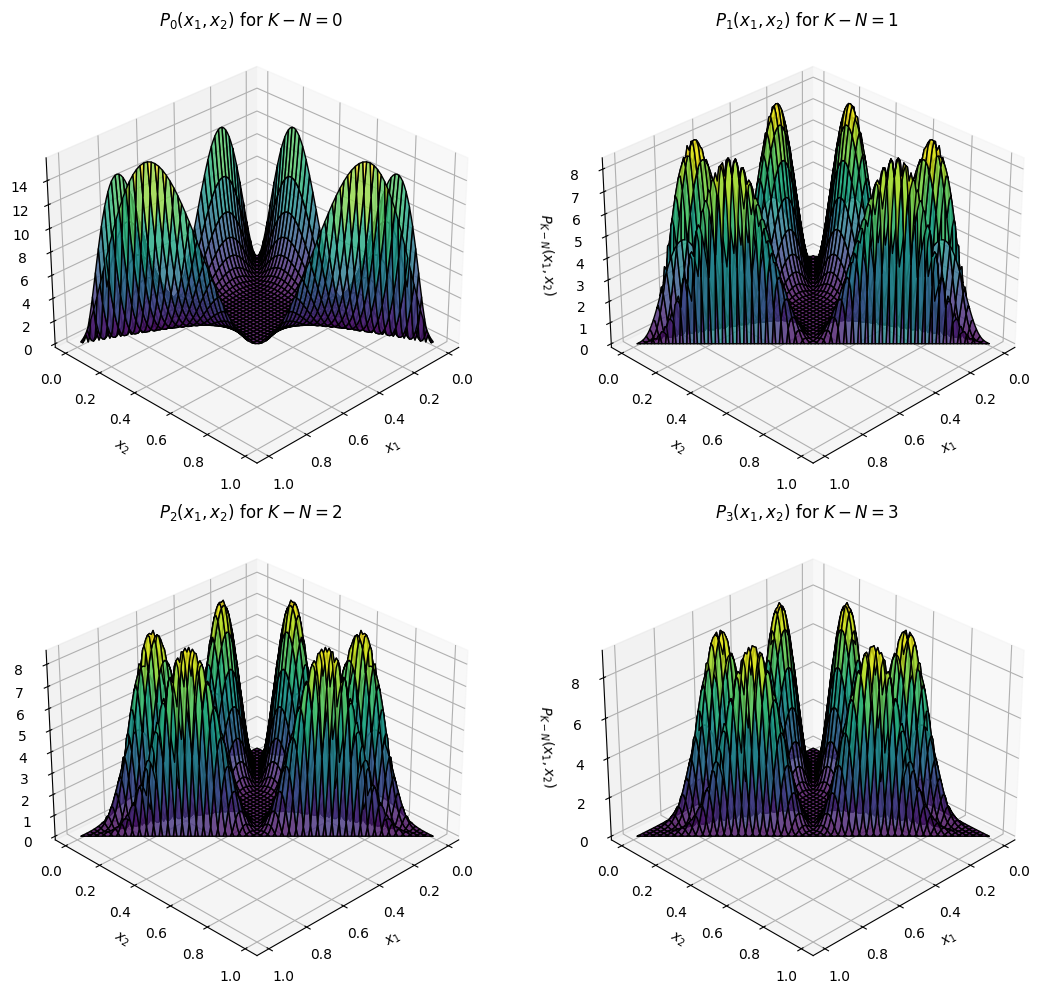

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import dblquad

# Define the unnormalized function P_D(x1, x2)
def P_D(x1, x2, D):
    if (x1 + x2) > 1:
        return 0  # Ensure function is zero outside valid region
    return ((1 - x1 - x2)**D * x1**D * x2**D *
            (x1 - x2)**2 * (x1 - (1 - x1 - x2))**2 * (x2 - (1 - x1 - x2))**2)

# Compute the normalization constant Z_D numerically
def compute_Z_D(D):
    integral, _ = dblquad(lambda x2, x1: P_D(x1, x2, D), 0, 1, lambda x1: 0, lambda x1: 1 - x1)
    return integral

# Define the normalized probability density function
def P_D_normalized(x1, x2, D):
    Z_D = compute_Z_D(D)
    return P_D(x1, x2, D) / Z_D if Z_D != 0 else 0  # Avoid division by zero

# Define grid points for x1 and x2
N = 100  # Resolution for smoother plots
x1_vals = np.linspace(0.01, 0.99, N)  # Avoid exact singularities
x2_vals = np.linspace(0.01, 0.99, N)
X1, X2 = np.meshgrid(x1_vals, x2_vals)

# Plot for D = 0, 1, 2, 3
fig, axes = plt.subplots(2, 2, subplot_kw={'projection': '3d'}, figsize=(12, 10))

D_values = [0, 1, 2, 3]
for i, D in enumerate(D_values):
    ax = axes[i // 2, i % 2]
    
    # Compute normalized P_D(x1, x2) while ensuring x1 + x2 <= 1
    Z = np.array([[P_D_normalized(x1, x2, D) for x1, x2 in zip(x1_row, x2_row)] for x1_row, x2_row in zip(X1, X2)])

    # Mask out invalid values
    Z[(X1 + X2) > 1] = np.nan

    # Plot the surface
    surf = ax.plot_surface(X1, X2, Z, cmap='viridis', edgecolor='k', alpha=0.8)

    # Labels and title
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax.set_zlabel(r"$P_{K-N}(x_1, x_2)$")
    ax.set_title(fr"$P_{D}(x_1, x_2)$ for $K-N={D}$")
    ax.view_init(elev=30, azim=45)  # Adjust initial view angle

# Show the plots
plt.tight_layout()
plt.show()


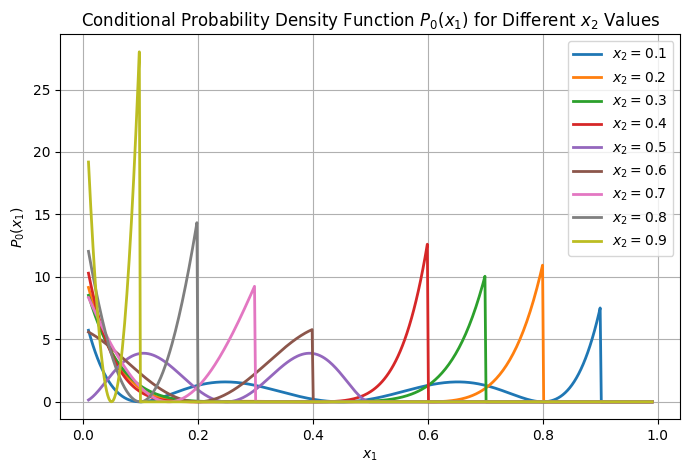

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P_D(x1, x2) for D=0
def P_D(x1, x2):
    if x1 + x2 > 1 or x1 <= 0 or x2 <= 0 or (1 - x1 - x2) <= 0:
        return 0  # Ensure function is zero outside valid region
    return (x1 - x2)**2 * (x1 - (1 - x1 - x2))**2 * (x2 - (1 - x1 - x2))**2

# Compute the normalization constant Z(x2) numerically
def compute_Z(x2):
    integral, _ = quad(lambda x1: P_D(x1, x2), 0, 1 - x2)
    return integral

# Define the normalized probability density function
def P_normalized(x1, x2):
    Z_x2 = compute_Z(x2)
    return P_D(x1, x2) / Z_x2 if Z_x2 != 0 else 0  # Avoid division by zero

# Define x1 values avoiding singularities
x1_vals = np.linspace(0.01, 0.99, 500)  # Avoid exact 0 and 1

# Different values of x2 to plot
x2_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

# Create the plot
plt.figure(figsize=(8, 5))

for x2 in x2_values:
    P_vals = np.array([P_normalized(x1, x2) for x1 in x1_vals])  # Compute normalized P(x1)
    plt.plot(x1_vals, P_vals, label=fr"$x_2 = {x2}$", linewidth=2)

# Labels and title
plt.xlabel(r"$x_1$")
plt.ylabel(r"$P_0(x_1|x_2)$")
plt.title(r"Conditional Probability Density Function $P_0(x_1|x_2)$ for Different $x_2$ Values")
plt.legend()
plt.grid()
plt.show()


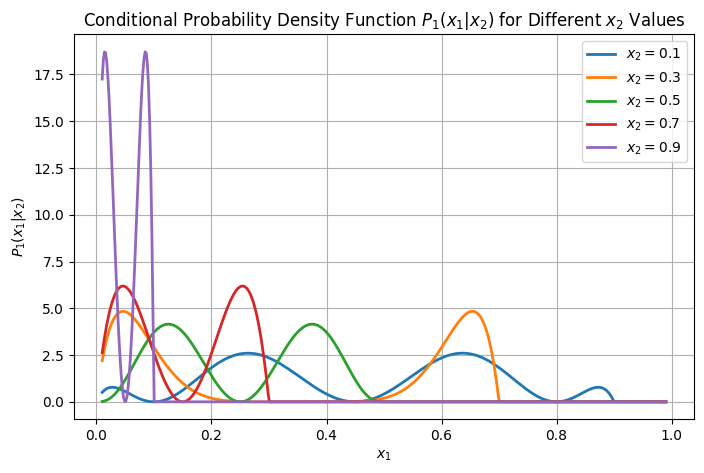

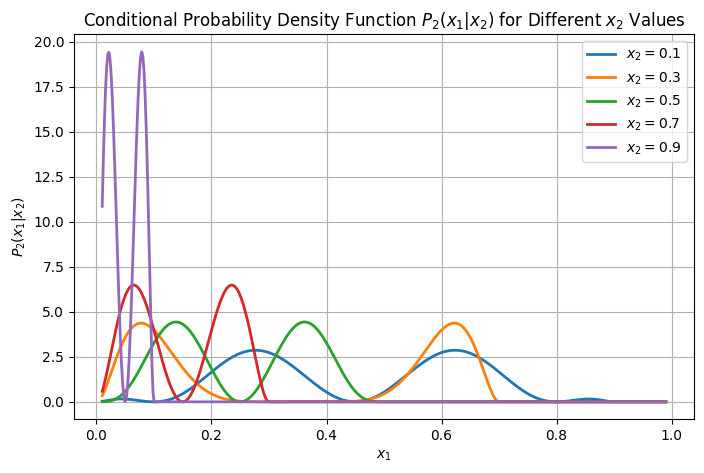

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P_D(x1, x2)
def P_D(x1, x2, D):
    if x1 + x2 > 1 or x1 <= 0 or x2 <= 0 or (1 - x1 - x2) <= 0:
        return 0  # Ensure function is zero outside valid region
    return (1 - x1 - x2)**D * x1**D * x2**D * (x1 - x2)**2 * (x1 - (1 - x1 - x2))**2 * (x2 - (1 - x1 - x2))**2

# Compute the normalization constant Z(x2) numerically
def compute_Z(x2, D):
    integral, _ = quad(lambda x1: P_D(x1, x2, D), 0, 1 - x2)
    return integral

# Define the normalized probability density function
def P_normalized(x1, x2, D):
    Z_x2 = compute_Z(x2, D)
    return P_D(x1, x2, D) / Z_x2 if Z_x2 != 0 else 0  # Avoid division by zero

# Define x1 values avoiding singularities
x1_vals = np.linspace(0.01, 0.99, 500)  # Avoid exact 0 and 1

# Different values of x2 to plot
x2_values = [ 0.1,  0.3, 0.5,  0.7, 0.9]

# Plot for D = 1
plt.figure(figsize=(8, 5))
for x2 in x2_values:
    P_vals = np.array([P_normalized(x1, x2, D=1) for x1 in x1_vals])  # Compute normalized P_D(x1)
    plt.plot(x1_vals, P_vals, label=fr"$x_2 = {x2}$", linewidth=2)

# Labels and title for D=1
plt.xlabel(r"$x_1$")
plt.ylabel(r"$P_1(x_1|x_2)$")
plt.title(r"Conditional Probability Density Function $P_1(x_1|x_2)$ for Different $x_2$ Values")
plt.legend()
plt.grid()
plt.show()

# Plot for D = 2
plt.figure(figsize=(8, 5))
for x2 in x2_values:
    P_vals = np.array([P_normalized(x1, x2, D=2) for x1 in x1_vals])  # Compute normalized P_D(x1)
    plt.plot(x1_vals, P_vals, label=fr"$x_2 = {x2}$", linewidth=2)

# Labels and title for D=2
plt.xlabel(r"$x_1$")
plt.ylabel(r"$P_2(x_1|x_2)$")
plt.title(r"Conditional Probability Density Function $P_2(x_1|x_2)$ for Different $x_2$ Values")
plt.legend()
plt.grid()
plt.show()


In [4]:
import numpy as np
from scipy.integrate import quad

# Define the probability density function P(x)
def P(x):
    if x <= 0 or x >= 1:
        return 0  # Ensure P(x) is valid in [0,1]
    return (1 / np.pi) * (1 / np.sqrt(x * (1 - x)))

# Define the entropy function H = - ∫ P(x) log P(x) dx
def entropy_integrand(x):
    px = P(x)
    return -px * np.log2(px) if px > 0 else 0  # Avoid log(0)

# Compute the Shannon entropy numerically
entropy, _ = quad(entropy_integrand, 0, 1)

# Print the result
print(f"Shannon Entropy H = {entropy:.6f} (in bits)")

Shannon Entropy H = -0.348504 (in bits)


In [5]:
import numpy as np
from scipy.integrate import quad

# Define the unnormalized function P_D(x)
def P_D(x, D):
    if x <= 0 or x >= 1:
        return 0  # Ensure P(x) is within [0,1]
    return (1 - x)**D * x**D * (x - (1 - x))**2

# Compute the normalization constant Z(D)
def compute_Z(D):
    integral, _ = quad(lambda x: P_D(x, D), 0, 1)
    return integral

# Compute the normalized probability density function
def P_normalized(x, D):
    Z_D = compute_Z(D)
    return P_D(x, D) / Z_D if Z_D != 0 else 0  # Avoid division by zero

# Compute Shannon entropy
def entropy_D(D):
    Z_D = compute_Z(D)  # Get normalization constant

    def entropy_integrand(x):
        p_x = P_D(x, D) / Z_D  # Normalized P_D(x)
        return -p_x * np.log2(p_x) if p_x > 0 else 0  # Avoid log(0)

    entropy, _ = quad(entropy_integrand, 0, 1)
    return entropy

# Compute and print entropy for D = 0,1,2,3
for D in range(4):
    H_D = entropy_D(D)
    print(f"Shannon Entropy for D={D}: H_{D} = {H_D:.6f} (in bits)")


Shannon Entropy for D=0: H_0 = -0.623166 (in bits)
Shannon Entropy for D=1: H_1 = -0.386446 (in bits)
Shannon Entropy for D=2: H_2 = -0.418331 (in bits)
Shannon Entropy for D=3: H_3 = -0.491172 (in bits)


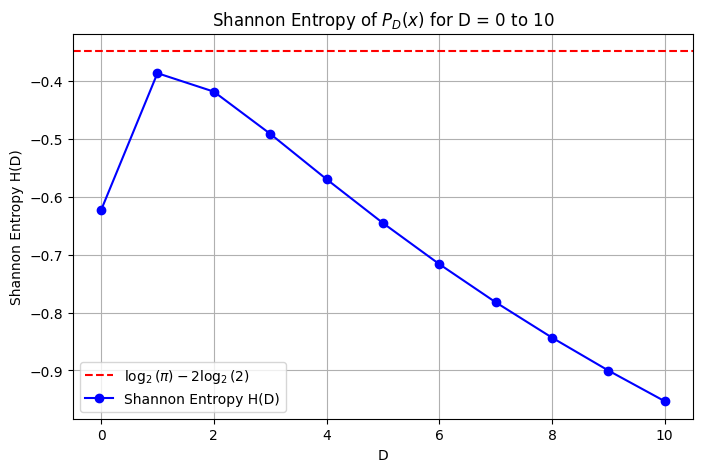

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the probability density function (before normalization)
def P_D(x, D):
    if x <= 0 or x >= 1:
        return 0  # Ensure P_D(x) is zero outside [0,1]
    return (1-x)**D * x**D * (x - (1-x))**2

# Compute the normalization constant Z(D)
def Z_D(D):
    integral, _ = quad(P_D, 0, 1, args=(D))
    return integral

# Normalized probability density function
def P_D_norm(x, D):
    return P_D(x, D) / Z_D(D)

# Compute Shannon entropy for given D
def shannon_entropy(D):
    def entropy_integrand(x):
        p = P_D_norm(x, D)
        return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)

    entropy, _ = quad(entropy_integrand, 0, 1)
    return entropy

# Compute entropies for D from 0 to 10
D_values = np.arange(0, 11)
H_values = [shannon_entropy(D) for D in D_values]
H_analytic = np.log2(np.pi) - 2 * np.log2(2)
# Plot the entropy as a function of D
plt.figure(figsize=(8, 5))
plt.axhline(y=H_analytic, color='r', linestyle='--', label=r'$\log_2(\pi) - 2\log_2(2)$')
plt.plot(D_values, H_values, marker='o', linestyle='-', color='b', label='Shannon Entropy H(D)')
plt.xlabel("D")
plt.ylabel("Shannon Entropy H(D)")
plt.title("Shannon Entropy of $P_D(x)$ for D = 0 to 10")
plt.grid()
plt.legend()
plt.show()


In [6]:
print(-2*np.log2(2)+np.log2(np.pi))

-0.3485038705276813


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt, log2
from scipy.integrate import nquad

In [3]:
def func(x2, x1):
    if x1+x2>=1 or x1==0 or x2==0:
        return 0
    return 1/(np.pi**2*sqrt(x1*(1-x1)*x2*(1-x1-x2)))

def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]

# Define the Shannon entropy function H_n
def entropy_integrand(*x):
    p = func(*x)
    return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)

h, abserror = nquad(entropy_integrand, [lim2, lim1])

                # opts=[opts0, opts1, opts2])
print(h)


-2.697007739743045


In [2]:
def func(x3, x2, x1):
    if x1+x2+x3>=1 or x1==0 or x2==0 or x3==0:
        return 0
    return 1/(np.pi**3*sqrt(x1*(1-x1)*x2*(1-x1-x2)*x3*(1-x1-x2-x3)))

def lim3(x2, x1):
    return [0, 1-x1-x2]

def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]

# Define the Shannon entropy function H_n
def entropy_integrand(*x):
    p = func(*x)
    return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)

h, abserror = nquad(entropy_integrand, [lim3, lim2, lim1])

                # opts=[opts0, opts1, opts2])
print(h)


/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/integrate/_quadpack_py.py:1272: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/integrate/_quadpack_py.py:1272: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be u

-7.045511675575186


In [3]:
print((h-3*log2(np.pi)))

-12.000000063992143


In [5]:
def func(x4, x3, x2, x1):
    if x1+x2+x3+x4>=1 or x1==0 or x2==0 or x3==0 or x4==0:
        return 0
    return 1/(np.pi**3*sqrt(x1*(1-x1)*x2*(1-x1-x2)*x3*(1-x1-x2-x3)*x4*(1-x1-x2-x3-x4)))

def lim4(x3,x2,x1):
    return [0, 1-x1-x2-x3]
    
def lim3(x2, x1):
    return [0, 1-x1-x2]

def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]

# Define the Shannon entropy function H_n
def entropy_integrand(*x):
    p = func(*x)
    return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)

h, abserror = nquad(entropy_integrand, [lim4, lim3, lim2, lim1])

                # opts=[opts0, opts1, opts2])
print(h)


KeyboardInterrupt: 

In [41]:
# Define the probability density function P(x_1, ..., x_{n-1})
def P(*x, n):
    x = x[0]
    if np.sum(x)>1:
        return 0
    sum_x = 0 
    prod = 1
    for k in range(n-1):
        if x[k]<0:
            return 0
        sum_x += x[k]
        prod *= (1 / np.pi) / np.sqrt(x[k] * (1 - sum_x))
    return prod
# x = 0.1, 0.2, 0.3
# print(P(x, n=4))

# Create a list of lim
def create_limite(n):
    return [0,1]

0.8294199674100734


In [ ]:
def generate_limits(n):
    limits = []

    # lim_0 (no arguments)
    def lim_0():
        return [0, 1]

    limits.append(lim_0)

    # lim_k (depends on x1, ..., xk)
    for k in range(1, n + 1):
        def lim_k(*args, k=k):  # Use default k to avoid late binding issue
            return [0, 1 - sum(args)]
        
        limits.append(lim_k)

    return limits


In [31]:

# Define the Shannon entropy function H_n
def entropy_integrand(*x, n):
    p = P(*x, n)
    return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)


# Function to compute Shannon entropy for a given n
def compute_entropy(n):
    # Define bounds dynamically based on previous integration values
    def f(*x): 
        return entropy_integrand(*x, n=n)

    # Generate the integration bounds for each variable
    # print(integration_limits)
    # Compute the entropy via numerical integration using lambda
    H_n, _ = nquad(f, ranges=[[0,1],[0,1]])
    # H_n, _ = nquad(lambda *x: 1, ranges=[[0,1],[0,1]])
    return H_n
print(compute_entropy(3))
# # Compute and plot Shannon entropy for different values of n
# n_values = range(2, 10)  # From n=2 to n=9 (since we use n-1 dimensions)
# H_values = [compute_entropy(n) for n in n_values]

# plt.figure(figsize=(8, 5))
# plt.plot(n_values, H_values, marker='o', linestyle='-', color='b', label=r'$H_n$')
# plt.xlabel("n")
# plt.ylabel("Shannon Entropy $H_n$")
# plt.title("Shannon Entropy as a Function of n")
# plt.grid(True)
# plt.legend()
# plt.show()

# # Print computed values
# for n, H in zip(n_values, H_values):
#     print(f"n = {n}, H_n = {H:.6f}")


0.2


In [26]:
def bounds(*args):
    sum_x = np.sum(args) if args else 0
    return (0, 1 - sum_x)
argument = np.array([0.5,0.4])
bounds(argument)


(0, np.float64(0.09999999999999998))

In [1]:
import numpy as np
from scipy.integrate import quad

def integrand(x):
    if x == 0:
        return 0  # To avoid singularity at x=0
    return (x * np.log2(x)) / (np.pi * np.sqrt(x * (1 - x)) )

# Compute the integral numerically
F1, error = quad(integrand, 0, 1)

print(f"Computed integral F1: {F1:.8f}")


Computed integral F1: -0.27865248


In [3]:
print(-1+1/(2*np.log(2)))

-0.2786524795555183


In [6]:
import numpy as np
from scipy.integrate import nquad

def integrand2(x2, x1):
    if x1+x2>=1 or x1==0 or x2==0:
        return 0
    return x2*np.log2(x2)/(np.pi**2*np.sqrt(x1*(1-x1)*x2*(1-x1-x2)))


def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]


h, abserror = nquad(integrand2, [lim2, lim1])

                # opts=[opts0, opts1, opts2])
print(h)


-0.27865247955574973


In [5]:
import numpy as np
from scipy.integrate import nquad

def integrand(x3, x2, x1):
    if x1+x2+x3>=1 or x1==0 or x2==0 or x3==0:
        return 0
    return x3*np.log2(x3)/(np.pi**3*np.sqrt(x1*(1-x1)*x2*(1-x1-x2)*x3*(1-x1-x2-x3)))

    
def lim3(x2, x1):
    return [0, 1-x1-x2]

def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]



h, abserror = nquad(integrand, [lim3, lim2, lim1])

                # opts=[opts0, opts1, opts2])

print(f"Computed integral F1: {h:.8f}")
a = 1/(2*np.log(2))-1 
print(f"Computed results analytic F1: {2*a/2**2:.8f}")


In [2]:
import numpy as np
a = 4*np.log(2)-2 
print(a)

0.7725887222397811


In [3]:

try:
    # Load the samples
    samplesP = np.load("sample_random_mps_L4_QDQdagger_nonordered.npy")
    samplesQ = np.load("sample_random_mps_L4_justD_nonordered.npy")
    # Compute KL divergence
    kl_div = compute_kl_divergence_from_samples(samplesP, samplesQ, bins=100, range_proba=[-5,5])
except FileNotFoundError:
    print(f"File not found. Skipping.")

print(kl_div)

0.04212854108318234


/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:851: ComplexWarning: Casting complex values to real discards the imaginary part
  indices = f_indices.astype(np.intp)
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  db = np.array(np.diff(bin_edges), float)


In [7]:
file_path_objective_errors_justD = 'objective_errors_random_mps_L4_justD_nonordered.npy'
file_path_objective_errors_QDQdagger = 'objective_errors_random_mps_L4_QDQdagger_nonordered.npy'
file_path_left_normalization_errors_random_mps_L4_justD = 'left_normalization_errors_random_mps_L4_justD_nonordered.npy'
file_path_left_normalization_errors_random_mps_L4_QDQdagger = 'left_normalization_errors_random_mps_L4_QDQdagger_nonordered.npy'


# Load the data
data_objective_errors_justD = np.load(file_path_objective_errors_justD)
data_objective_errors_QDQdagger = np.load(file_path_objective_errors_QDQdagger)
data_left_normalization_errors_random_mps_L4_justD = np.load(file_path_left_normalization_errors_random_mps_L4_justD)
data_left_normalization_errors_random_mps_L4_QDQdagger = np.load(file_path_left_normalization_errors_random_mps_L4_QDQdagger)
# Compute the average and standard deviation
average_objective_errors_justD = np.mean(data_objective_errors_justD)
std_objective_errors_justD = np.std(data_objective_errors_justD)

average_objective_errors_QDQdagger = np.mean(data_objective_errors_QDQdagger)
std_objective_errors_QDQdagger = np.std(data_objective_errors_QDQdagger)

average_left_normalization_errors_justD = np.mean(data_left_normalization_errors_random_mps_L4_justD)
std_left_normalization_errors_justD = np.std(data_left_normalization_errors_random_mps_L4_justD)

average_left_normalization_errors_QDQdagger = np.mean(data_left_normalization_errors_random_mps_L4_QDQdagger)
std_left_normalization_errors_QDQdagger = np.std(data_left_normalization_errors_random_mps_L4_QDQdagger)

# Print results
print(f"Objective errors justD     -> mean: {average_objective_errors_justD:.3e}, std: {std_objective_errors_justD:.3e}")
print(f"Objective errors QDQdagger -> mean: {average_objective_errors_QDQdagger:.3e}, std: {std_objective_errors_QDQdagger:.3e}")
print(f"Left norm. errors justD    -> mean: {average_left_normalization_errors_justD:.3e}, std: {std_left_normalization_errors_justD:.3e}")
print(f"Left norm. errors QDQdagger-> mean: {average_left_normalization_errors_QDQdagger:.3e}, std: {std_left_normalization_errors_QDQdagger:.3e}")


Objective errors justD     -> mean: 1.171e+00, std: 1.457e+00
Objective errors QDQdagger -> mean: 1.222e+00, std: 1.429e+00
Left norm. errors justD    -> mean: 5.165e-08, std: 7.094e-07
Left norm. errors QDQdagger-> mean: 1.441e-07, std: 2.136e-06


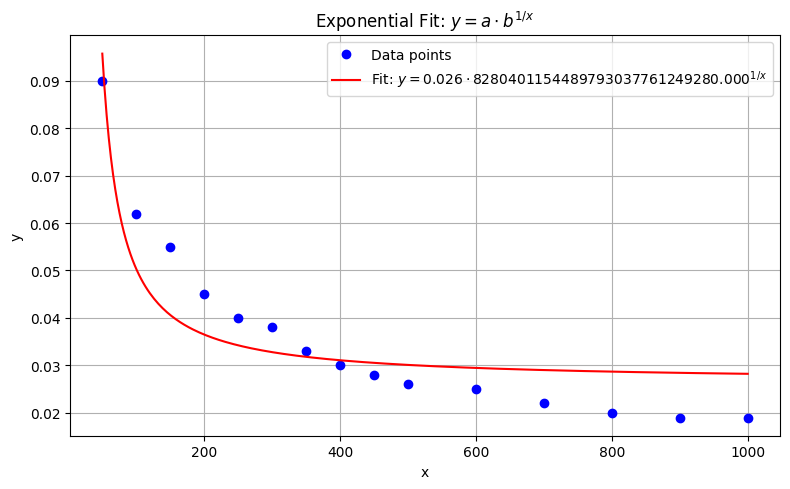

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

# Given data
x = np.array([50, 100, 150, 200, 250,
             300, 350, 400, 450, 500, 
             600, 700, 800, 900, 1000])
y = np.array([0.09, 0.062, 0.055, 0.045, 0.04,
             0.038, 0.033, 0.03, 0.028, 0.026,
             0.025, 0.022, 0.02, 0.019, 0.019 ])

# Model: y = a * b^(1/x)
def model(x, a, b):
    return a * b**(1/x)

# Fit the model
popt, _ = curve_fit(model, x, y, p0=[0.1, 0.1])
a_fit, b_fit = popt

# Generate fitted curve
x_fit = np.linspace(min(x), max(x), 300)
y_fit = model(x_fit, a_fit, b_fit)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x, y, 'o', label='Data points', color='blue')
plt.plot(x_fit, y_fit, '-', label=fr'Fit: $y = {a_fit:.3f} \cdot {b_fit:.3f}^{{1/x}}$', color='red')

# Labels and formatting
plt.xlabel('x')
plt.ylabel('y')
plt.title(r'Exponential Fit: $y = a \cdot b^{1/x}$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


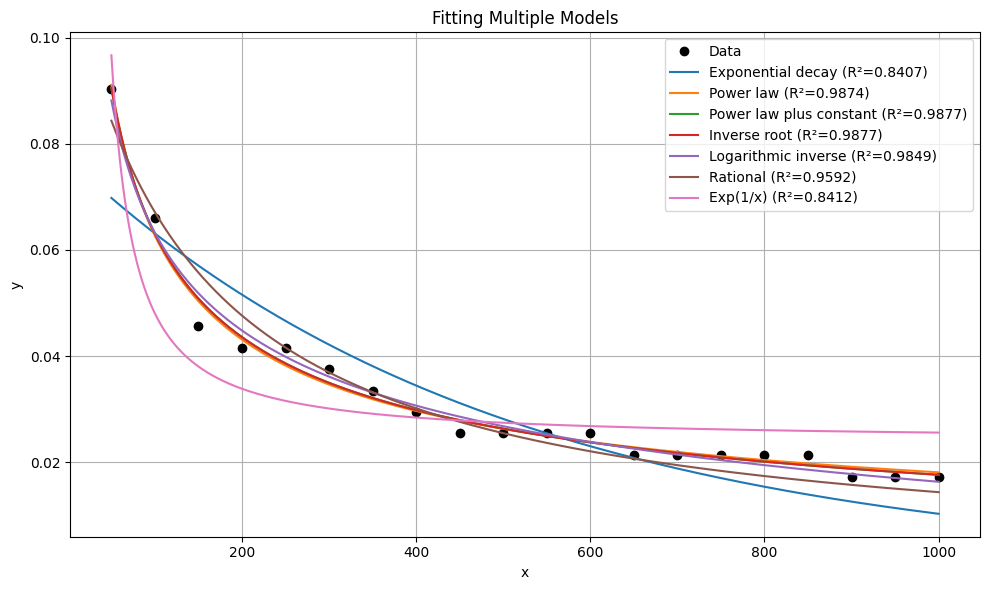


Fitted Model Parameters:
Exponential decay         | R² = 0.8407 | Parameters: 0.077220, 0.002019
Power law                 | R² = 0.9874 | Parameters: 0.754138, 0.540190
Power law plus constant   | R² = 0.9877 | Parameters: 0.663936, 0.499940, -0.003400
Inverse root              | R² = 0.9877 | Parameters: 0.664063, -0.003395
Logarithmic inverse       | R² = 0.9849 | Parameters: 0.648471, -0.077584
Rational                  | R² = 0.9592 | Parameters: 16.402488, 144.415072
Exp(1/x)                  | R² = 0.8412 | Parameters: 0.023835, 2584913733994999456759738793984.000000


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Data for the Gaussian distribution around the maximally entangled state point.
x = np.array([50, 100, 150, 200, 250,
             300, 350, 400, 450, 500, 
             550, 600, 650, 700, 750,
             800, 850, 900, 950, 1000
            ])
y = np.array([0.0903, 0.0660, 0.0457, 0.0416, 0.0416,
            0.0376, 0.0335, 0.0294, 0.0254, 0.0254,
             0.0254, 0.0254, 0.0213, 0.0213, 0.0213,
             0.0213, 0.0213, 0.0172, 0.0172, 0.0172 
            ])

# Data for the uniform distribution around the maximally entangled state point.
# x = np.array([50, 100, 150, 200, 250, 
#             300, 350, 400, 450, 500, 
#             600, 700, 800, 900, 1000])
# y = np.array([0.3476, 0.2457, 0.2049, 0.1845, 0.1641,
#             0.1437, 0.1233, 0.1233, 0.1233, 0.1029,
#             0.1029, 0.1029, 0.0826, 0.0826, 0.0826])

# Define models and initial guesses
models = {
    "Exponential decay": (lambda x, a, b: a * np.exp(-b * x), [0.1, 0.001]),
    "Power law": (lambda x, a, b: a * x**(-b), [0.1, 0.5]),
    "Power law plus constant": (lambda x, a, b, c: a * x**(-b) + c, [0.1, 0.5, 0]),
    "Inverse root": (lambda x, a, c: a / np.sqrt(x) + c, [0.1, 0.01]),
    "Logarithmic inverse": (lambda x, a, c: a / np.log(x) + c, [0.1, 0.01]),
    "Rational": (lambda x, a, b: a / (x + b), [0.1, 1]),
    "Exp(1/x)": (lambda x, a, b: a * b**(1/x), [0.01, 5])
}

# R² calculator
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

x_fit = np.linspace(min(x), max(x), 500)
plt.figure(figsize=(10, 6))
plt.plot(x, y, 'o', label='Data', color='black')

# Store results for printing
results = []

# Fit and plot each model
for name, (func, p0) in models.items():
    try:
        popt, _ = curve_fit(func, x, y, p0=p0)
        y_pred = func(x, *popt)
        y_fit = func(x_fit, *popt)
        r2 = r_squared(y, y_pred)
        plt.plot(x_fit, y_fit, label=f'{name} (R²={r2:.4f})')
        results.append((name, popt, r2))
    except Exception as e:
        print(f"{name} failed: {e}")

plt.xlabel('x')
plt.ylabel('y')
plt.title('Fitting Multiple Models')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Print fitted parameters after plotting
print("\nFitted Model Parameters:")
for name, params, r2 in results:
    param_str = ", ".join([f"{p:.6f}" for p in params])
    print(f"{name:25s} | R² = {r2:.4f} | Parameters: {param_str}")


n=1000

Power law                 | R² = 0.9874 | Parameters: 0.754138, 0.540190

Power law plus constant   | R² = 0.9877 | Parameters: 0.663936, 0.499940, -0.003400

n=750

Power law                 | R² = 0.9863 | Parameters: 0.744467, 0.537362

Power law plus constant   | R² = 0.9865 | Parameters: 0.673181, 0.504414, -0.002997

n=500

Power law                 | R² = 0.9824 | Parameters: 0.739852, 0.535983 

Power law plus constant   | R² = 0.9827 | Parameters: 0.643900, 0.487501, -0.005112

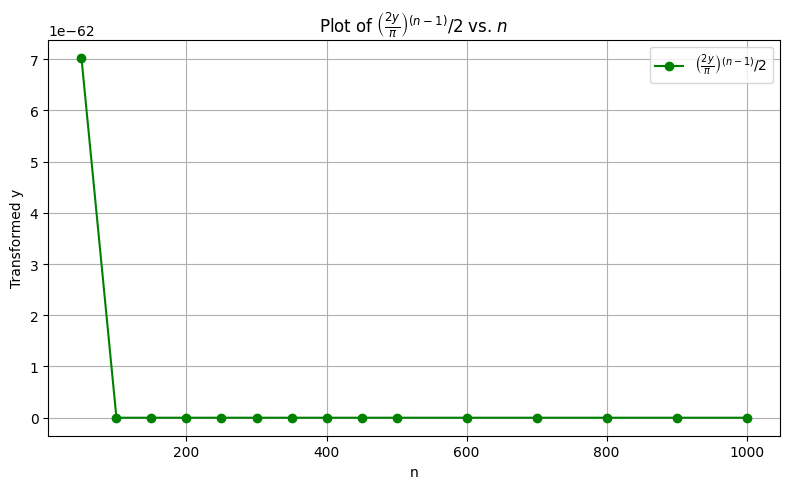

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Data for the Gaussian distribution around the maximally entangled state point.
x = np.array([50, 100, 150, 200, 250,
             300, 350, 400, 450, 500, 
             600, 700, 800, 900, 1000])
y = np.array([0.09, 0.062, 0.055, 0.045, 0.04,
             0.038, 0.033, 0.03, 0.028, 0.026,
             0.025, 0.022, 0.02, 0.019, 0.019 ])

# Compute transformed y values: (2y/pi)^((n-1)/2)
transformed_y = (2 * y / np.pi) ** (x - 1) / 2

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x, transformed_y, marker='o', linestyle='-', color='green',
         label=r'$\left( \frac{2y}{\pi} \right)^{(n-1)}/2$')

# Labels and title
plt.xlabel('n')
plt.ylabel('Transformed y')
plt.title(r'Plot of $\left( \frac{2y}{\pi} \right)^{(n-1)}/2$ vs. $n$')

# Grid
plt.grid(True)

# Legend and layout
plt.legend()
plt.tight_layout()
plt.show()


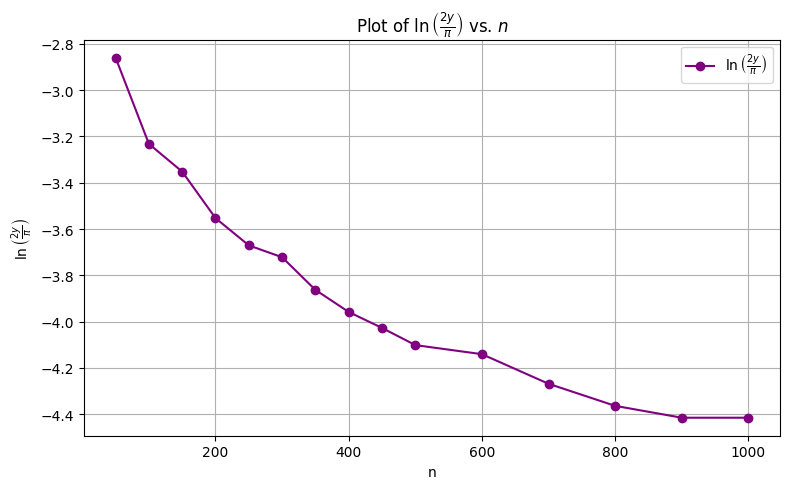

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Data for the Gaussian distribution around the maximally entangled state point.
x = np.array([50, 100, 150, 200, 250,
             300, 350, 400, 450, 500, 
             600, 700, 800, 900, 1000])
y = np.array([0.09, 0.062, 0.055, 0.045, 0.04,
             0.038, 0.033, 0.03, 0.028, 0.026,
             0.025, 0.022, 0.02, 0.019, 0.019 ])

# Compute ln(2y/pi)
ln_y = np.log(2 * y / np.pi)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x, ln_y, marker='o', linestyle='-', color='purple',
         label=r'$\ln\left( \frac{2y}{\pi} \right)$')

# Labels and title
plt.xlabel('n')
plt.ylabel(r'$\ln\left( \frac{2y}{\pi} \right)$')
plt.title(r'Plot of $\ln\left( \frac{2y}{\pi} \right)$ vs. $n$')

# Grid
plt.grid(True)

# Legend and layout
plt.legend()
plt.tight_layout()
plt.show()


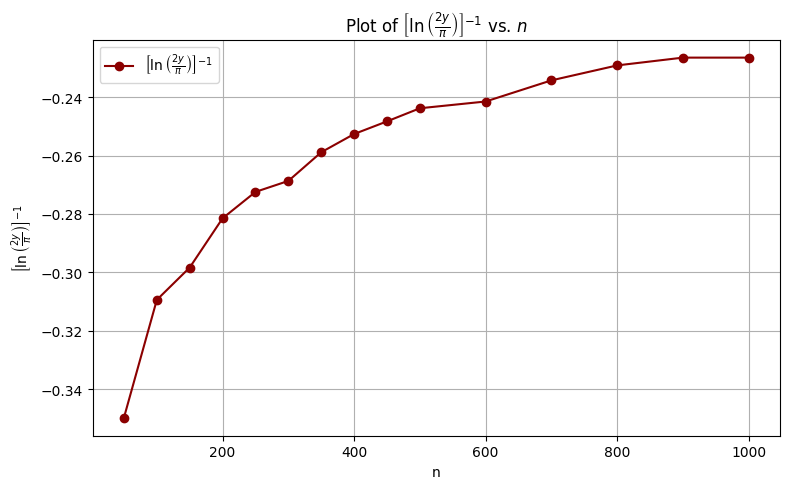

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Data for the Gaussian distribution around the maximally entangled state point.
x = np.array([50, 100, 150, 200, 250,
             300, 350, 400, 450, 500, 
             600, 700, 800, 900, 1000])
y = np.array([0.09, 0.062, 0.055, 0.045, 0.04,
             0.038, 0.033, 0.03, 0.028, 0.026,
             0.025, 0.022, 0.02, 0.019, 0.019 ])

# Compute inverse of ln(2y/pi)
ln_y_inv = 1 / np.log(2 * y / np.pi)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x, ln_y_inv, marker='o', linestyle='-', color='darkred',
         label=r'$\left[\ln\left( \frac{2y}{\pi} \right)\right]^{-1}$')

# Labels and title
plt.xlabel('n')
plt.ylabel(r'$\left[\ln\left( \frac{2y}{\pi} \right)\right]^{-1}$')
plt.title(r'Plot of $\left[\ln\left( \frac{2y}{\pi} \right)\right]^{-1}$ vs. $n$')

# Grid
plt.grid(True)

# Legend and layout
plt.legend()
plt.tight_layout()
plt.show()


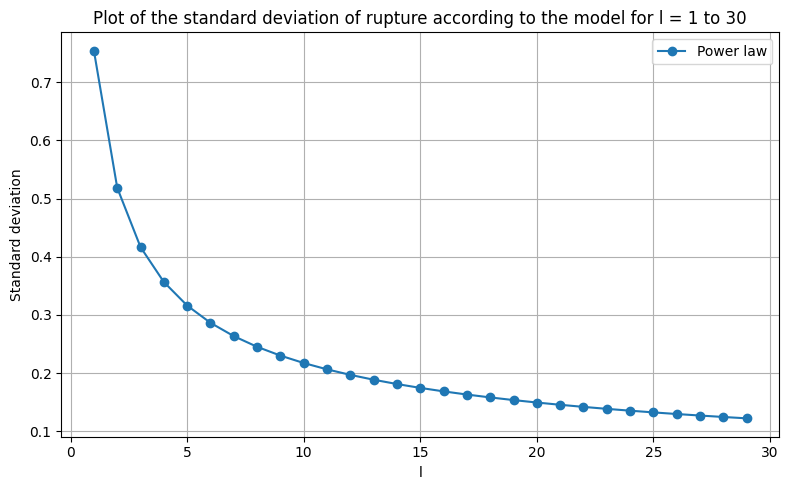

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Define the range of n
l_limit = 30
l = np.arange(1, l_limit)

# Define your functions

def standard_deviation_rupture_pt_power_law(n):
    """
    Power law. lambda x, a, b: a * x**(-b)
    R² = 0.9874 | Parameters: 0.754138, 0.540190 
    """
    a = 0.754138
    b = 0.540190 
    return a * n**(-b)

def standard_deviation_rupture_pt_inverse_root(l):
    """
    Inverse root. lambda x, a, c: a / np.sqrt(x) + c
    R² = 0.9877 | Parameters: 0.664063, -0.003395 
    """
    n = 2**l
    a = 0.664063
    c = -0.003395 
    return a / np.sqrt(n) + c

def standard_deviation_rupture_pt_logarithmic_inverse(n):
    """
    Logarithmic inverse. lambda x, a, c: a / np.log(x) + c
    R² = 0.9849 | Parameters: 0.648471, -0.077584
    """
    a = 0.648471
    c = -0.077584
    return a / np.log(n) + c

# Evaluate functions
y1 = standard_deviation_rupture_pt_power_law(n)
# y2 = standard_deviation_rupture_pt_inverse_root(n)
# y3 = standard_deviation_rupture_pt_logarithmic_inverse(n)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(n, y1, label="Power law", marker='o')
# plt.plot(n, y2, label="Inverse root", marker='s')
# plt.plot(n, y3, label="Logarithmic inverse", marker='^')

plt.xlabel("l")
plt.ylabel("Standard deviation")
plt.title(f"Plot of the standard deviation of rupture according to the model for l = 1 to {l_limit}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [2]:
print(min(y1))
print(min(y2))
print(min(y3))

0.01784621440378225
0.01736710897476835
0.015983778621784808


In [1]:
import numpy as np
import matplotlib.pyplot as plt
# all_corr_matrices = np.load("corr_matrices_N10_n_samples100_standard_deviation0.17185859.npy")
corr_matrices_1 = np.load('corr_matrices_N10_n_samples100.npy')
corr_matrices_2 = np.load('corr_matrices_N10_n_samples100_former_method.npy')
corr_matrices_3 = np.load('corr_matrices_N10_n_samples15.npy')

# Data for the Gaussian distribution around the maximally entangled state point.
all_corr_matrices = np.concatenate((corr_matrices_1, corr_matrices_2, corr_matrices_3), axis=0)            



print(all_corr_matrices.shape)  # e.g., (10, 10, 10)

corr_matrix = all_corr_matrices[0]

def plot_corr_decay(corr_matrix):
    N = corr_matrix.shape[0]
    max_dist = N - 1
    avg_corr = []

    for d in range(1, max_dist):
        values = [corr_matrix[i, i + d] for i in range(N - d)]
        avg_corr.append(np.mean(values))

    plt.semilogy(range(1, max_dist), avg_corr, 'o-')
    plt.xlabel('Distance |i - j|')
    plt.ylabel('Average C^{zz}(i,j)')
    plt.title('Correlation Decay')
    plt.grid(True)
    plt.show()


(215, 10, 10)


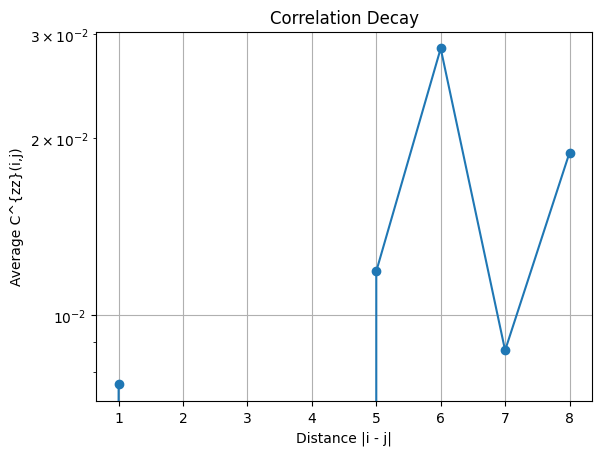

In [10]:
plot_corr_decay(corr_matrix)

In [16]:
def plot_avg_corr_decay(all_corr_matrices):
    """
    Plot average correlation decay from a 3D array of shape (n_samples, N, N)
    """
    n_samples, N, _ = all_corr_matrices.shape
    max_dist = N #  - 1
    avg_corr = []
    std_corr = []

    for d in range(1, max_dist):
        values = []
        for sample in range(n_samples):
            for i in range(N - d):
                values.append(abs(all_corr_matrices[sample, i, i + d]))
                # values.append(all_corr_matrices[sample, i, i + d])
                # print(f"i: {i}, d: {d}, values: {values}")
        std_corr.append(np.std(values))
        avg_corr.append(np.mean(values))
        
    fig, ax = plt.subplots()
    plt.plot(range(1, max_dist), avg_corr, 'o-')
    
    # plt.errorbar(range(1, max_dist), avg_corr, yerr=std_corr, fmt='o-', capsize=4, label='Mean ± Std')
    # plt.plot(range(1, max_dist), avg_corr, fmt='o-', capsize=4, label='Mean ± Std')
    plt.xlabel('Distance |i - j|')
    ax.set_yscale('log', base=2)
    ax.set_xscale('log', base=2)
    secax = ax.twiny()
    secax.plot(range(1, max_dist), avg_corr, 'o-', color = 'red')

    plt.ylabel('Average $C^{zz}(i,j)$')
    plt.title(f'Average Correlation Decay Over {n_samples} Samples')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    plt.show()

/tmp/ipykernel_275231/849000054.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


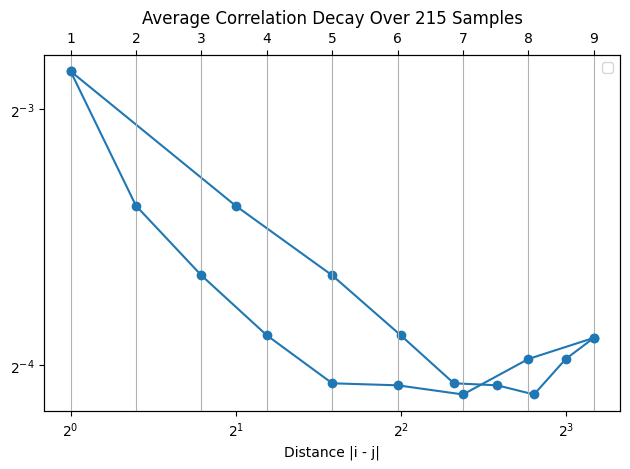

In [17]:
plot_avg_corr_decay(all_corr_matrices)

In [12]:
# Let us compute the time of the correlation matrix computations.
import numpy as np
import time

a = np.complex128(1 + 2j)
b = np.complex128(3 + 4j)

N = 10**6
start = time.time()
for _ in range(N):
    c = a * b
end = time.time()

print(f"Average time per multiplication: {(end - start)/N * 1e9:.2f} ns")

Average time per multiplication: 153.95 ns


In [2]:
L=12
time_insecond = 158.82*8**L*10**(-9)*(L*(L-1))/2
print(f"{time_insecond} seconds")
print(f"so {time_insecond/60} minutes")
print(f"so {time_insecond/3600} heures")
print(f"so {time_insecond/3600/24} jours")
print(f"so {time_insecond/3600/24/365} ans")

720325.8014839604 seconds
so 12005.430024732672 minutes
so 200.0905004122112 heures
so 8.337104183842134 jours
so 0.02284138132559489 ans


In [1]:
import numpy as np

# # Load:
data = np.load('rupture_point_from_10_to_1000_n_simulation1000.npz')
print(data['n_array'])
print(data['worst_diameter_array'])
print(data['worst_r2_array'])

[ 10  20  30  40  50  60  70  80  90 100 110 120 130 140 150 160 170 180
 190 200 210 220 230 240 250 260 270 280 290 300 310 320 330 340 350 360
 370 380 390 400 410 420 430 440 450 460 470 480 490 500 510 520 530 540
 550 560 570 580 590 600 610 620 630 640 650 660 670 680 690 700 710 720
 730 740 750 760 770 780 790 800 810 820 830 840 850 860 870 880 890 900
 910 920 930 940 950 960 970 980 990]
[0.17185859 0.12160606 0.12361616 0.10351515 0.08140404 0.08140404
 0.07135354 0.07135354 0.06934343 0.06331313 0.05728283 0.05728283
 0.05728283 0.04723232 0.04924242 0.04924242 0.04723232 0.04522222
 0.04321212 0.04120202 0.04120202 0.03919192 0.04120202 0.03919192
 0.03718182 0.03919192 0.03919192 0.03517172 0.03316162 0.03517172
 0.03115152 0.03316162 0.03316162 0.03115152 0.02914141 0.03316162
 0.02914141 0.02914141 0.02914141 0.02914141 0.02914141 0.03115152
 0.02713131 0.02914141 0.02914141 0.02713131 0.02713131 0.02713131
 0.02713131 0.02713131 0.02512121 0.02512121 0.02512121 0.025

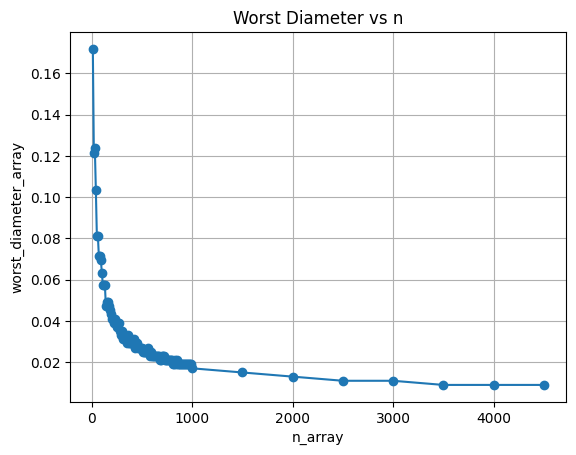

In [21]:
import matplotlib.pyplot as plt

data = np.load('rupture_point_from_10_to_1000_n_simulation1000.npz')
data2 = np.load('rupture_point_from_1000_to_5000_n_simulations1000.npz')
# Data for the Gaussian distribution around the maximally entangled state point.
x = np.concatenate((data['n_array'], data2['n_array']), axis=0)            
y = np.concatenate((data['worst_diameter_array'], data2['worst_diameter_array']), axis=0)

plt.plot(x, y, marker='o')
plt.xlabel('n_array')
plt.ylabel('worst_diameter_array')
plt.title('Worst Diameter vs n')
plt.grid(True)
plt.show()


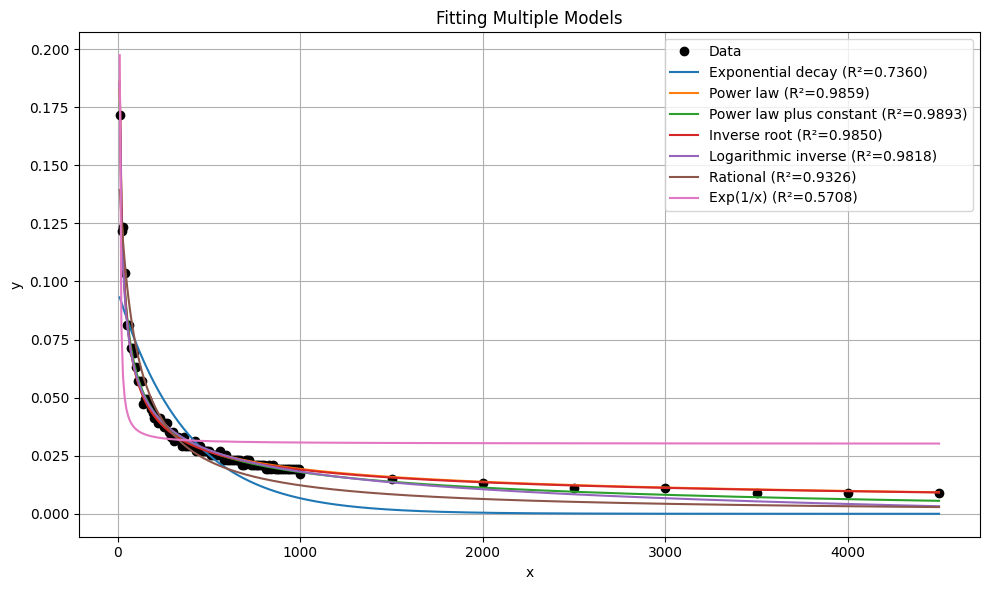


Fitted Model Parameters:
Exponential decay         | R² = 0.7360 | Parameters: 0.095703, 0.002663
Power law                 | R² = 0.9859 | Parameters: 0.560014, 0.487388
Power law plus constant   | R² = 0.9893 | Parameters: 0.492159, 0.425090, -0.008193
Inverse root              | R² = 0.9850 | Parameters: 0.586658, 0.000440
Logarithmic inverse       | R² = 0.9818 | Parameters: 0.575029, -0.065110
Rational                  | R² = 0.9326 | Parameters: 13.284898, 85.315593
Exp(1/x)                  | R² = 0.5708 | Parameters: 0.030108, 146448993.593539


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


# # Load:
data = np.load('rupture_point_from_10_to_1000_n_simulation1000.npz')
data2 = np.load('rupture_point_from_1000_to_5000_n_simulations1000.npz')
# Data for the Gaussian distribution around the maximally entangled state point.
x = np.concatenate((data['n_array'], data2['n_array']), axis=0)            
y = np.concatenate((data['worst_diameter_array'], data2['worst_diameter_array']), axis=0)


# Define models and initial guesses
models = {
    "Exponential decay": (lambda x, a, b: a * np.exp(-b * x), [0.1, 0.001]),
    "Power law": (lambda x, a, b: a * x**(-b), [0.1, 0.5]),
    "Power law plus constant": (lambda x, a, b, c: a * x**(-b) + c, [0.1, 0.5, 0]),
    "Inverse root": (lambda x, a, c: a / np.sqrt(x) + c, [0.1, 0.01]),
    "Logarithmic inverse": (lambda x, a, c: a / np.log(x) + c, [0.1, 0.01]),
    "Rational": (lambda x, a, b: a / (x + b), [0.1, 1]),
    "Exp(1/x)": (lambda x, a, b: a * b**(1/x), [0.01, 5])
}

# R² calculator
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

x_fit = np.linspace(min(x), max(x), 500)
plt.figure(figsize=(10, 6))
plt.plot(x, y, 'o', label='Data', color='black')

# Store results for printing
results = []

# Fit and plot each model
for name, (func, p0) in models.items():
    try:
        popt, _ = curve_fit(func, x, y, p0=p0)
        y_pred = func(x, *popt)
        y_fit = func(x_fit, *popt)
        r2 = r_squared(y, y_pred)
        plt.plot(x_fit, y_fit, label=f'{name} (R²={r2:.4f})')
        results.append((name, popt, r2))
    except Exception as e:
        print(f"{name} failed: {e}")

plt.xlabel('x')
plt.ylabel('y')
plt.title('Fitting Multiple Models')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Print fitted parameters after plotting
print("\nFitted Model Parameters:")
for name, params, r2 in results:
    param_str = ", ".join([f"{p:.6f}" for p in params])
    print(f"{name:25s} | R² = {r2:.4f} | Parameters: {param_str}")


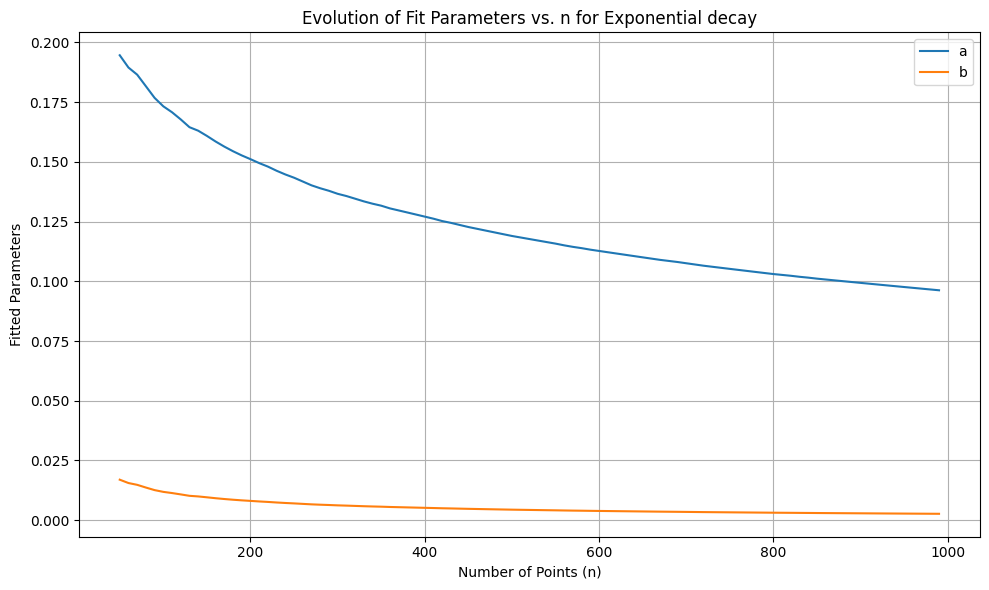

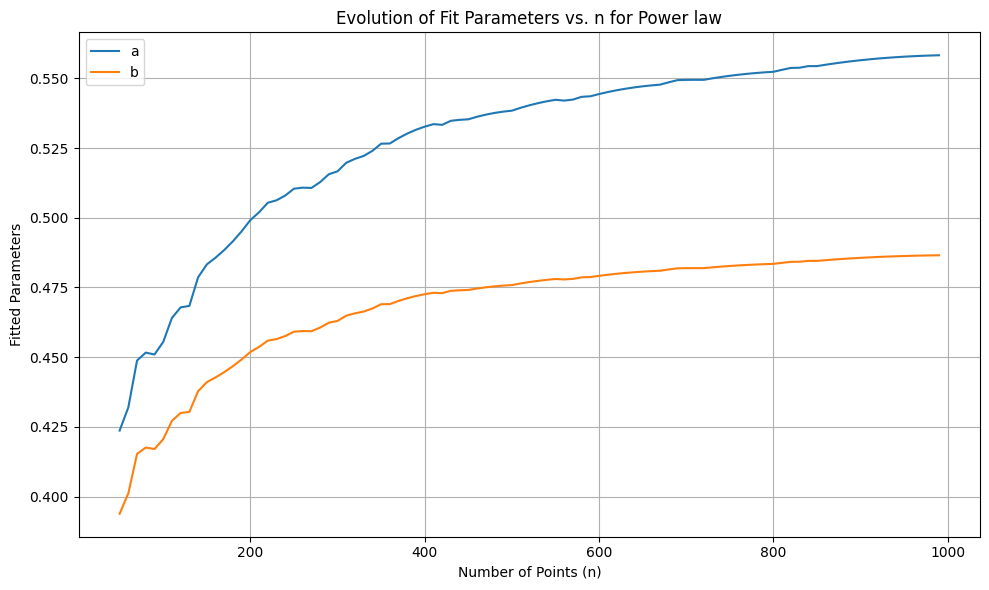

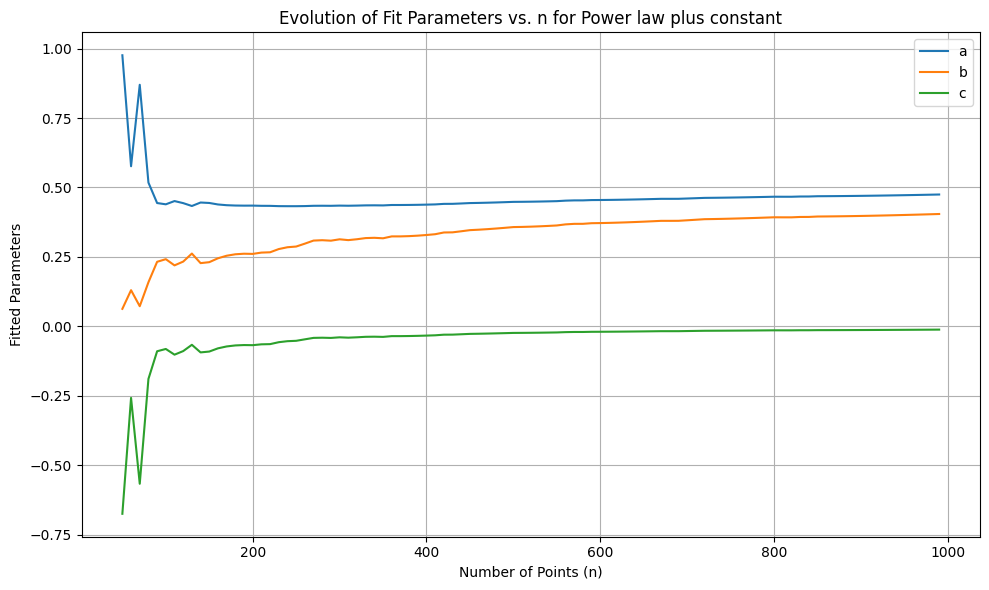

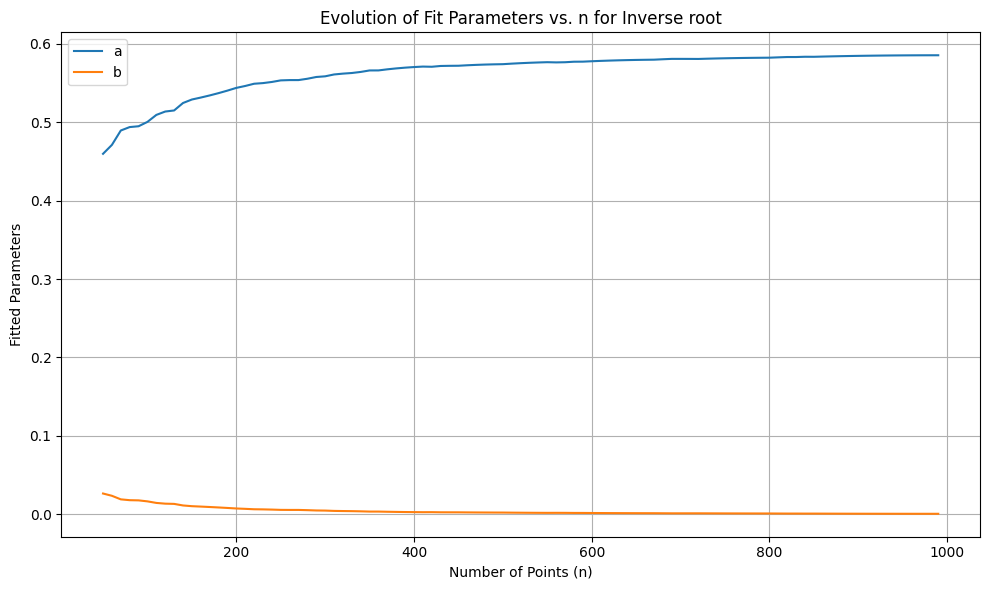

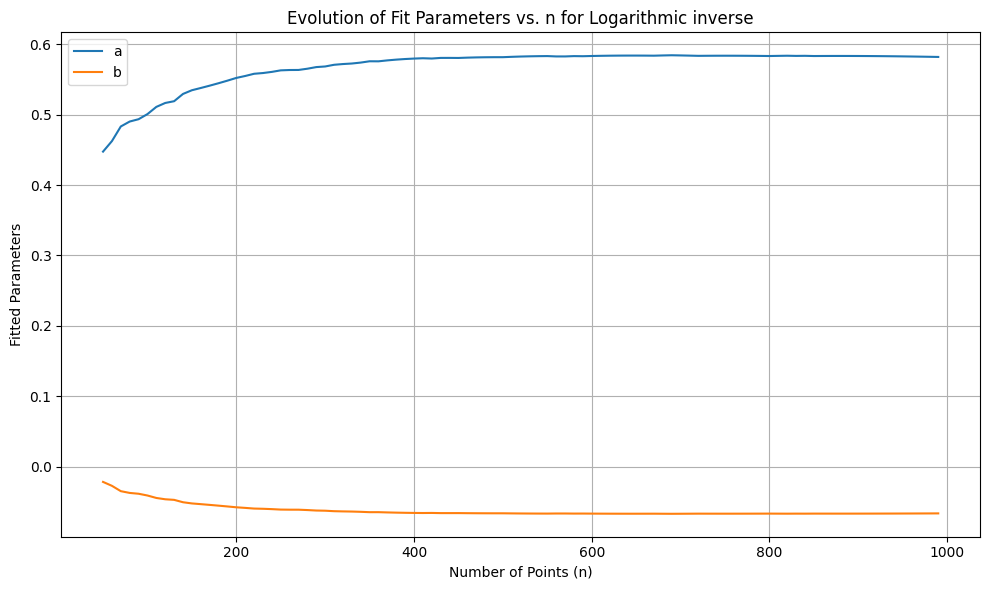

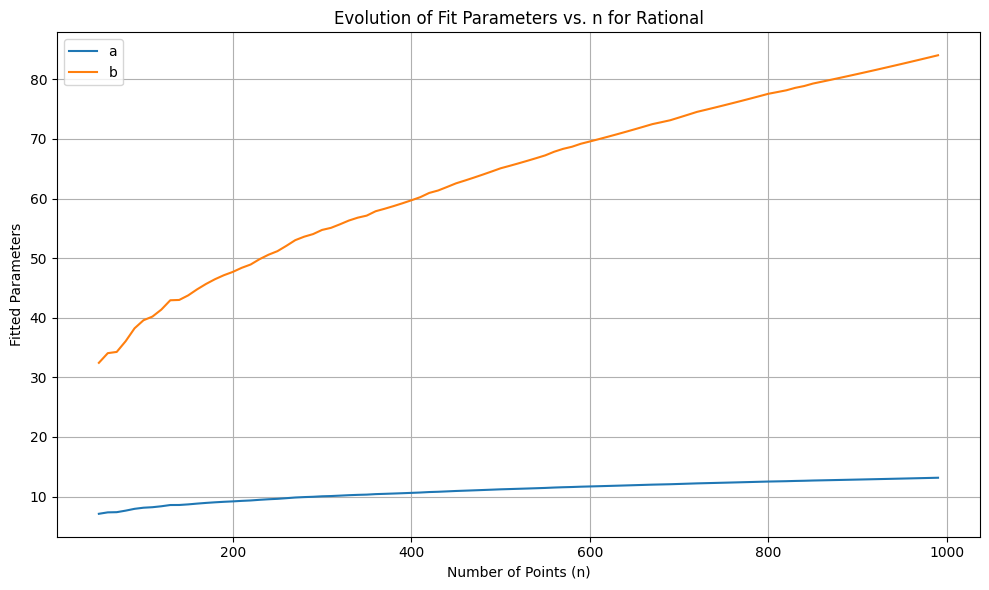

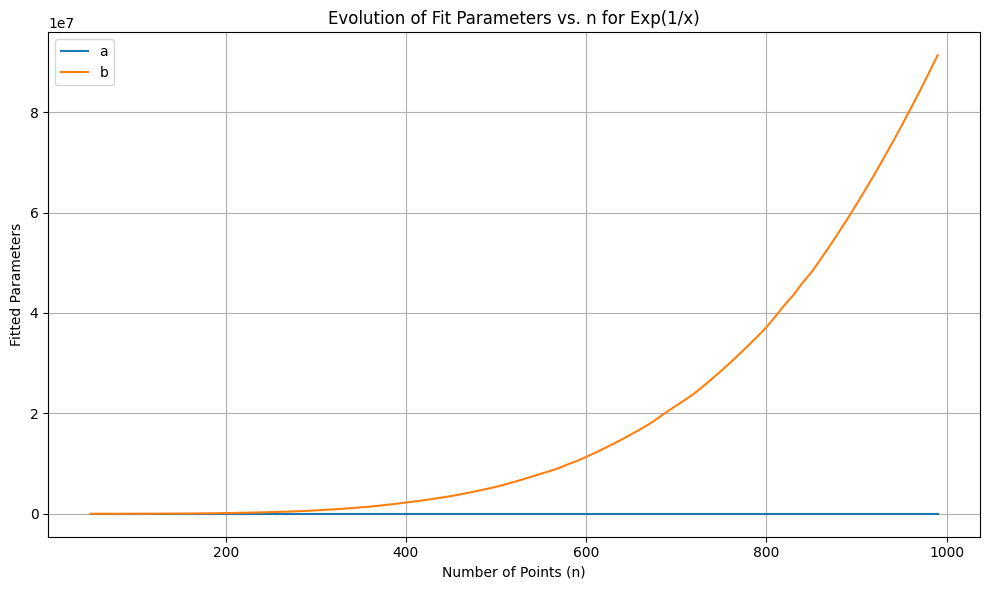

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

data = np.load('rupture_point_from_10_to_1000_n_simulation1000.npz')
data2 = np.load('rupture_point_from_1000_to_5000_n_simulations1000.npz')
# Data for the Gaussian distribution around the maximally entangled state point.
# x = np.concatenate((data['n_array'], data2['n_array']), axis=0)            
# y = np.concatenate((data['worst_diameter_array'], data2['worst_diameter_array']), axis=0)
x = data['n_array']
y = data['worst_diameter_array']

N = len(x)
a_vals, b_vals, c_vals = [], [], []
ns = range(5, N + 1)
x_ns = x[4:]  # start from 5 to avoid poor fits with tiny samples


# Fit and plot each model
for name, (func, p0) in models.items():
    a_vals, b_vals, c_vals = [], [], []
    for n in ns:
        try:
            popt, _ = curve_fit(func, x[:n], y[:n], p0=p0, maxfev=10000)
            # popt, _ = curve_fit(models["Power law plus constant"], , p0=(1, 1, 0)
            # popt, _ = curve_fit(models["Inverse root"], x[:n], y[:n], p0=(1, 1, 0), maxfev=10000)
            a_vals.append(popt[0])
            b_vals.append(popt[1])
            if len(p0)>2:
                c_vals.append(popt[2])
        except RuntimeError:
            # In case the fit fails, append NaN or skip
            a_vals.append(np.nan)
            b_vals.append(np.nan)
            if len(p0)>2:
                c_vals.append(np.nan)

    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(x_ns, a_vals, label='a')
    plt.plot(x_ns, b_vals, label='b')
    if len(p0)>2:
        plt.plot(x_ns, c_vals, label='c')
    plt.xlabel('Number of Points (n)')
    plt.ylabel('Fitted Parameters')
    plt.title(f'Evolution of Fit Parameters vs. n for {name}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()





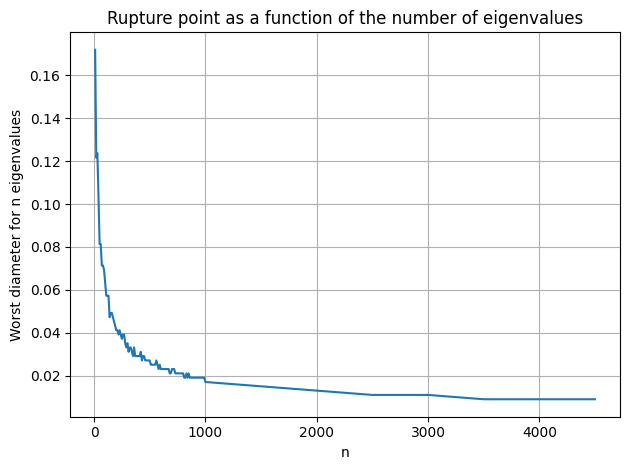

In [8]:
data = np.load('rupture_point_from_10_to_1000_n_simulation1000.npz')
data2 = np.load('rupture_point_from_1000_to_5000_n_simulations1000.npz')
# Data for the Gaussian distribution around the maximally entangled state point.
x = np.concatenate((data['n_array'], data2['n_array']), axis=0)            
y = np.concatenate((data['worst_diameter_array'], data2['worst_diameter_array']), axis=0)

plt.plot(x, y, label='b')

plt.xlabel('n')
plt.ylabel('Worst diameter for n eigenvalues')
plt.title(f'Rupture point as a function of the number of eigenvalues')
# plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:
print(data['n_array'])
print(data['worst_diameter_array'])

[ 10  20  30  40  50  60  70  80  90 100 110 120 130 140 150 160 170 180
 190 200 210 220 230 240 250 260 270 280 290 300 310 320 330 340 350 360
 370 380 390 400 410 420 430 440 450 460 470 480 490 500 510 520 530 540
 550 560 570 580 590 600 610 620 630 640 650 660 670 680 690 700 710 720
 730 740 750 760 770 780 790 800 810 820 830 840 850 860 870 880 890 900
 910 920 930 940 950 960 970 980 990]
[0.17185859 0.12160606 0.12361616 0.10351515 0.08140404 0.08140404
 0.07135354 0.07135354 0.06934343 0.06331313 0.05728283 0.05728283
 0.05728283 0.04723232 0.04924242 0.04924242 0.04723232 0.04522222
 0.04321212 0.04120202 0.04120202 0.03919192 0.04120202 0.03919192
 0.03718182 0.03919192 0.03919192 0.03517172 0.03316162 0.03517172
 0.03115152 0.03316162 0.03316162 0.03115152 0.02914141 0.03316162
 0.02914141 0.02914141 0.02914141 0.02914141 0.02914141 0.03115152
 0.02713131 0.02914141 0.02914141 0.02713131 0.02713131 0.02713131
 0.02713131 0.02713131 0.02512121 0.02512121 0.02512121 0.025

In [6]:
from scipy.optimize import minimize
import distribution.distribution_functions.random_mps as rmps


def random_point_on_the_n_sphere_in_a_disk_local(n: int, r: float=1):
    """
    Input:
    n (int): dimension of the space of the n-sphere. We should have angles_center.size = n-1. 
    r (float): rayon of the n-sphere. By default, 1.

    Output: 
    new_coordinates (np.array): A random point uniformly distributed around the point whose coordinates are angles_center 
                    in a disk of diameter diameter_disk on the n-sphere. The point is given via its Cartesian 
                    coordinates. 
    """
    # if rayon_disk > min(math.asin(1/math.sqrt(n)), np.pi/4):
    #     raise ValueError(f"The input value diameter_disk must be smaller than {2*math.asin(1/math.sqrt(n))} and pi/2")
    # Generate the coordinates of the maximal
    # Step 1: Generate the angles
    angles_center = rmps.generate_angle_maximally_entangled_eigenvalues(n)  
    # Step 2: Compute x1, x2, ..., xn
    new_coordinates = np.zeros(n)
    product_sin = 1  # Initialize the cumulative product of sin terms
    for i in range(n - 1):
        if i > 0:
            product_sin *= np.sin(angles_center[i - 1])
        new_coordinates[i] = r * product_sin * np.cos(angles_center[i])
    # Last coordinate xn with full product of sines
    if n == 1:
        new_coordinates[-1] = r * product_sin
    else:
        new_coordinates[-1] = r * product_sin * np.sin(angles_center[-1])
    return new_coordinates




def matrices_A_maximally_entangled_states(L, d=2):
    """
    Input:
    L (int): number of site (assumed even for simplicity for the moment).
    d (int): dimension of the hilbert space of a single site (for qubit d=2).
    
    Output:
    list_M (list): list of the tensors M_optimized ordered increasingly. 
    list_objective_error
    list_left_normalization_error
    rho_middle
    
    The function constructs in the decreasing order, the matrix M to produce a random product state. 
    """
    rho_l = np.array([[1]]) # Initial density matrix rho_L.
    list_M = [] # I store the matrices M in a list. 
    list_objective_error = []
    list_left_normalization_error = []
    
    for l in range(L, int(L/2), -1): # l> L/2
        d_L_minus_l_plus_1 = int(d**(L-l+1))
        s_i = np.square(random_point_on_the_n_sphere_in_a_disk_local(d_L_minus_l_plus_1))
        # Random unitary matrix (rho is a density matrix so Hermitian so diagonalizable by a unitary matrix).
        Q = rmps.random_unitary_matrix(d_L_minus_l_plus_1) 
        D = np.diag(s_i) # Uniform distribution, to be modified later. 
        rho_l_minus_one = Q @ D @ np.conj(Q).T

        # Initialize M randomly 
        M_initial = np.random.randn(d_L_minus_l_plus_1, d_L_minus_l_plus_1) + 1j * np.random.randn(d_L_minus_l_plus_1, d_L_minus_l_plus_1)
        M_initial = M_initial.flatten()
        # Constraints dictionary for scipy.optimize
        constraints = {'type': 'eq', 'fun': rmps.constraint_M_after_middle, 'args': (d, l, L)}
        # Optimize M to minimize the loss while satisfying the constraint
        result = minimize(rmps.loss_function_M_after_middle, M_initial, args=(rho_l, rho_l_minus_one, d, l, L), 
                          constraints=constraints, method='SLSQP', options={'disp': False})
        # Put options={'disp': True} to have the information about the optimization. 
        # Reshape the result back to the original shape
        M_optimized = result.x.reshape(d_L_minus_l_plus_1, d_L_minus_l_plus_1)
        list_M.insert(0, rmps.reshape_array_after_middle(M_optimized, d, l))
        list_objective_error.insert(0,rmps.check_objective_after_middle(M_optimized, rho_l, rho_l_minus_one, d, l, L))
        list_left_normalization_error.insert(0, rmps.check_left_normalization_after_middle(M_optimized, d, l, L))
        rho_l = rho_l_minus_one
    rho_middle = rho_l

    for l in range(int(L/2), 0, -1): #l <= L/2
        d_l = int(d**(l))
        d_l_minus_one = int(d**(l-1))
        s_i = np.square(random_point_on_the_n_sphere_in_a_disk_local(d_l_minus_one))
        # Random unitary matrix (rho is a density matrix so Hermitian so diagonalizable by a unitary matrix).
        Q = rmps.random_unitary_matrix(d_l_minus_one) 
        D = np.diag(s_i) # Uniform distribution, to be modified later. 
        rho_l_minus_one = Q @ D @ np.conj(Q).T
        
        # Find M minimising our objective function with the left normalization constraint. 
        M_initial = np.random.randn(d_l, d_l) + 1j * np.random.randn(d_l, d_l)
        M_initial = M_initial.flatten()
        # Constraints dictionary for scipy.optimize
        constraints = {'type': 'eq', 'fun': rmps.constraint_M_before_middle, 'args': (d, l)}
        # Optimize M to minimize the loss while satisfying the constraint
        result = minimize(rmps.loss_function_M_before_middle, M_initial, args=(rho_l, rho_l_minus_one, d, l), 
                          constraints=constraints, method='SLSQP', options={'disp': False})
        # Reshape the result back to the original shape
        M_optimized = result.x.reshape(d_l, d_l)
        list_M.insert(0, rmps.reshape_array_before_middle(M_optimized, d, l))
        list_objective_error.insert(0, rmps.check_objective_before_middle(M_optimized, rho_l, rho_l_minus_one, d, l))
        list_left_normalization_error.insert(0, rmps.check_left_normalization_before_middle(M_optimized, d, l))
        rho_l = rho_l_minus_one

    return list_M, list_objective_error, list_left_normalization_error, rho_middle





In [7]:
L = 10
d=2
list_M, list_objective_error, list_left_normalization_error, rho_middle = matrices_A_maximally_entangled_states(L, d)

/project/th-scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)


In [8]:
print(list_M)

[array([[[ 0.85887044,  0.51179949]],

       [[ 0.51207632, -0.85918356]]]), array([[[ 0.31968099, -0.61103463, -0.60309725,  0.40100896],
        [ 0.279266  , -0.03781519, -0.39547569, -0.87434055]],

       [[-0.23429826, -0.79033276,  0.49934986, -0.26657784],
        [ 0.87460855,  0.0237605 ,  0.48005839,  0.06107558]]]), array([[[ 0.56574927, -0.03563011,  0.27006018,  0.41063131,
         -0.33575279, -0.30695526, -0.40306529,  0.26036194],
        [ 0.02010614, -0.25015583, -0.58735144,  0.39258283,
         -0.06187661,  0.5912277 , -0.26572899,  0.11759632],
        [-0.29074479, -0.52237826, -0.06005193, -0.02599976,
          0.24934855, -0.40560376, -0.54557996, -0.33746162],
        [ 0.24817156, -0.77390109,  0.10620053, -0.20384781,
          0.07397549,  0.03104129,  0.41053046,  0.33435307]],

       [[ 0.15315439, -0.15514187, -0.00908706, -0.40710107,
         -0.7071672 ,  0.18560674, -0.06605595, -0.4977135 ],
        [ 0.58298262,  0.01164928, -0.06147821,  0.2

In [69]:
state = rmps.vector_state_from_mps(list_M, L, 2)

In [1]:
import numpy as np
from scipy.linalg import svd

def entanglement_entropy(state, i, d=2):
    """
    Compute the von Neumann entropy between sites 0,...,i-1 and the rest,
    and compare to the maximum possible value.
    
    Returns:
        entropy: actual von Neumann entropy
        S_max: maximum possible entropy at the cut
    """
    L = int(np.log2(len(state)) / np.log2(d))
    assert 0 < i < L, "Cut must be between 0 and L"
    
    dim_A = d**i
    dim_B = d**(L - i)
    psi_matrix = state.reshape((dim_A, dim_B))

    U, S, Vh = svd(psi_matrix, full_matrices=False)
    probs = S**2
    probs = probs[probs > 1e-12]
    entropy = -np.sum(probs * np.log2(probs))

    S_max = np.log2(min(dim_A, dim_B))
    
    return entropy, S_max


In [3]:
L=10
for i in range(1, L):
    entropy, S_max = entanglement_entropy(state, i, d=2)
    print(entropy)
    print(f"S_max = {S_max}")

NameError: name 'state' is not defined